# Photo-Sensor Feature Optimization Notebook

**Objective:** Systematically search the feasible input space using two pre-trained ML models (`Best_Model_Responsivity.pkl` and `Best_Model_log10_Detectivity.pkl`) to identify the device configuration(s) yielding the best combined photo-sensor performance. The models are trained on the SCAPS-1D dataset (Notebook 1). 


---
### Consistency with the training notebook (`photosensor_ML_clean.ipynb`)
| Item | Finding |
|---|---|
| Feature order | `['Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength', 'CBO', 'VBO']` |
| Feature scaling | **None** for tree models (DT, GB). Only `StandardScaler` inside a `Pipeline` for the LR baseline (not used here). |
| Detectivity target | Trained on `log10(Detectivity)`. Inverse: `10^prediction`. |
| Responsivity target | Raw `Responsivity` (A/W). No transform. |
| CBO / VBO | Engineered from `Affinity` and `Eg` with fixed interface constants. |
| Best Responsivity model | `DecisionTreeRegressor` (saved as `Best_Model_Responsivity.pkl`) |
| Best Detectivity model | `GradientBoostingRegressor` (saved as `Best_Model_log10_Detectivity.pkl`) |


## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import joblib

os.makedirs('results', exist_ok=True)

print('All libraries imported successfully.')


All libraries imported successfully.


## 2. Load Saved Models

In [2]:
# ============================================================
# Load the two pre-trained best models.
#
#  Best_Model_Responsivity.pkl       -> DecisionTreeRegressor
#    Trained directly on raw Responsivity (A/W). No target transform.
#    No input scaling needed (tree model, raw features).
#
#  Best_Model_log10_Detectivity.pkl  -> GradientBoostingRegressor
#    Trained on log10(Detectivity).
#    Inverse-transform: Detectivity = 10 ** prediction.
#    No input scaling needed (tree model, raw features).
# ============================================================

MODEL_R_PATH = 'Best_Model_Responsivity.pkl'
MODEL_D_PATH = 'Best_Model_log10_Detectivity.pkl'

for path in [MODEL_R_PATH, MODEL_D_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f'Model file not found: {path}')

model_R = joblib.load(MODEL_R_PATH)   # DecisionTreeRegressor
model_D = joblib.load(MODEL_D_PATH)   # GradientBoostingRegressor

print('Responsivity model :', type(model_R).__name__)
print('Detectivity  model :', type(model_D).__name__)
print()
print('Both models loaded successfully.')


Responsivity model : DecisionTreeRegressor
Detectivity  model : GradientBoostingRegressor

Both models loaded successfully.


## 3. Load Dataset / Define Search Space

In [3]:
# ============================================================
# Discrete candidate values for the design search.
# The models are evaluated only at these grid points.
# ============================================================

Eg_values       = np.arange(0.8, 1.21, 0.05)
Affinity_values = np.arange(3.9, 4.51, 0.05)
t_values        = np.round(np.arange(0.6, 1.451, 0.05), 2)   # 0.60 to 1.45 um
N_A_values      = [1e14, 1e15, 1e16, 1e17, 1e18]             # cm-3, one value per decade
N_t_values      = [1e14, 1e15, 1e16, 1e17]                   # cm-3, one value per decade
Wavelength_values = list(range(300, 2001, 20))   # 86 values: 300, 320, ..., 2000 nm

total_rows = (
    len(Eg_values) * len(Affinity_values) * len(t_values)
    * len(N_A_values) * len(N_t_values) * len(Wavelength_values)
)

print('Search space dimensions:')
print(f'  Eg         : {len(Eg_values)} values  -> {Eg_values}')
print(f'  Affinity   : {len(Affinity_values)} values  -> {Affinity_values}')
print(f'  t          : {len(t_values)} values  -> {t_values}')
na_str = [f'{v:.0e}' for v in N_A_values]
nt_str = [f'{v:.0e}' for v in N_t_values]
print(f'  N_A        : {len(N_A_values)} values  -> ' + str(na_str))
print(f'  N_t        : {len(N_t_values)} values  -> ' + str(nt_str))
print(f'  Wavelength : {len(Wavelength_values)} values  -> 300-2000 nm, step 20')
print()
print(f'Full Cartesian grid size : {total_rows:,} rows')


Search space dimensions:
  Eg         : 9 values  -> [0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2 ]
  Affinity   : 13 values  -> [3.9  3.95 4.   4.05 4.1  4.15 4.2  4.25 4.3  4.35 4.4  4.45 4.5 ]
  t          : 18 values  -> [0.6  0.65 0.7  0.75 0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2  1.25
 1.3  1.35 1.4  1.45]
  N_A        : 5 values  -> ['1e+14', '1e+15', '1e+16', '1e+17', '1e+18']
  N_t        : 4 values  -> ['1e+14', '1e+15', '1e+16', '1e+17']
  Wavelength : 86 values  -> 300-2000 nm, step 20

Full Cartesian grid size : 3,622,320 rows


## 4. Reproduce Preprocessing

In [4]:
# ============================================================
# 4a. Build the full Cartesian grid
# ============================================================

print('Building Cartesian grid ...')

grid_tuples = list(itertools.product(
    Eg_values, Affinity_values, t_values,
    N_A_values, N_t_values, Wavelength_values
))

df_grid = pd.DataFrame(
    grid_tuples,
    columns=['Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength']
)

n_rows = len(df_grid)
n_cols = df_grid.shape[1]
print(f'Grid built : {n_rows:,} rows x {n_cols} columns')

# ============================================================
# 4b. Compute physics-informed interface features.
#     Formulas extracted verbatim from photosensor_ML_Nahid.ipynb, Cell 5.
# ============================================================

CHI_ZNSE = 4.09   # eV  - Electron affinity of ZnSe (window layer)
CHI_MOS2 = 3.80   # eV  - Electron affinity of MoS2 (BSF layer)
EG_MOS2  = 1.62   # eV  - Bandgap of MoS2 (BSF layer)

# Conduction-band offset at ZnSe/absorber interface
df_grid['CBO'] = df_grid['Affinity'] - CHI_ZNSE

# Valence-band offset at absorber/MoS2 interface
df_grid['VBO'] = CHI_MOS2 - df_grid['Affinity'] + EG_MOS2 - df_grid['Eg']

print()
print('CBO / VBO computed from fixed interface constants:')
print(f'  CBO = Affinity - CHI_ZNSE  (CHI_ZNSE = {CHI_ZNSE} eV)')
print(f'  VBO = CHI_MOS2 - Affinity + EG_MOS2 - Eg  (CHI_MOS2={CHI_MOS2}, EG_MOS2={EG_MOS2} eV)')
print()
print('Grid preview (first 3 rows):')
display(df_grid.head(3))


Building Cartesian grid ...


Grid built : 3,622,320 rows x 6 columns

CBO / VBO computed from fixed interface constants:
  CBO = Affinity - CHI_ZNSE  (CHI_ZNSE = 4.09 eV)
  VBO = CHI_MOS2 - Affinity + EG_MOS2 - Eg  (CHI_MOS2=3.8, EG_MOS2=1.62 eV)

Grid preview (first 3 rows):


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO
0,0.8,3.9,0.6,1.000000e+14,1.000000e+14,300,-0.19,0.72
1,0.8,3.9,0.6,1.000000e+14,1.000000e+14,320,-0.19,0.72
2,0.8,3.9,0.6,1.000000e+14,1.000000e+14,340,-0.19,0.72


## 5. Verify Model Inputs

In [5]:
# ============================================================
# Feature ordering must match the training pipeline exactly.
# Extracted from photosensor_ML_Nahid.ipynb, Cells 5 & 10.
# ============================================================

FEATURES = ['Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength', 'CBO', 'VBO']

X_opt = df_grid[FEATURES].copy()

# Sanity checks
assert X_opt.shape == (total_rows, len(FEATURES)), \
    f'Shape mismatch: expected ({total_rows}, {len(FEATURES)}), got {X_opt.shape}'
assert not X_opt.isna().any().any(), 'Feature matrix contains NaN values.'
assert np.isfinite(X_opt.to_numpy(dtype=float)).all(), \
    'Feature matrix contains non-finite values.'

print('Input verification passed.')
print(f'  Shape      : {X_opt.shape}')
print(f'  NaN values : {X_opt.isna().sum().sum()}')
print()
print('Feature ranges:')
display(X_opt.describe().T[['min', 'max']])


Input verification passed.
  Shape      : (3622320, 8)
  NaN values : 0

Feature ranges:


,min,max
Eg,8.000000e-01,1.200000e+00
Affinity,3.900000e+00,4.500000e+00
t,6.000000e-01,1.450000e+00
N_A,1.000000e+14,1.000000e+18
N_t,1.000000e+14,1.000000e+17
Wavelength,3.000000e+02,2.000000e+03
CBO,-1.900000e-01,4.100000e-01
VBO,-2.800000e-01,7.200000e-01


## 6. Define Prediction Functions

In [6]:
def predict_responsivity(X):
    """
    Predict Responsivity (A/W).
    Model: DecisionTreeRegressor.
    Target trained on raw Responsivity -- no inverse transform needed.
    No feature scaling (tree-based model).
    """
    return model_R.predict(X[FEATURES])


def predict_detectivity(X):
    """
    Predict Detectivity (Jones).
    Model: GradientBoostingRegressor trained on log10(Detectivity).
    Inverse transform: Detectivity = 10 ** log10_prediction.
    No feature scaling (tree-based model).
    """
    log10_pred = model_D.predict(X[FEATURES])
    return np.power(10.0, log10_pred)


print('Prediction functions defined.')
print('  predict_responsivity  -> raw A/W (DecisionTree)')
print('  predict_detectivity   -> Jones   (GradientBoosting + 10^x inverse)')


Prediction functions defined.
  predict_responsivity  -> raw A/W (DecisionTree)
  predict_detectivity   -> Jones   (GradientBoosting + 10^x inverse)


## 7. Define Optimization Objective

In [7]:
# ============================================================
# Multi-objective scoring using min-max normalization.
#
# Rationale:
#   Responsivity is in A/W (typically 0-1 range).
#   Detectivity is in Jones (typically 1e10-1e14).
#   Summing raw values would be completely dominated by Detectivity.
#
# Method:
#   1. Scale each metric independently to [0, 1] via min-max.
#   2. Combined score = 0.5 * norm_R + 0.5 * norm_D  (equal weights).
#   3. Rank by descending combined score.
# ============================================================

def minmax_normalize(arr):
    """Scale array to [0, 1] using global min and max."""
    lo, hi = arr.min(), arr.max()
    if np.isclose(lo, hi):
        return np.zeros_like(arr, dtype=float)
    return (arr - lo) / (hi - lo)


print('Objective: 0.5 * minmax(Responsivity) + 0.5 * minmax(Detectivity)')
print('Both metrics equally weighted after independent [0,1] scaling.')


Objective: 0.5 * minmax(Responsivity) + 0.5 * minmax(Detectivity)
Both metrics equally weighted after independent [0,1] scaling.


## 8. Perform Optimization (Exhaustive Grid Search)

In [8]:
print(f'Running predictions on {len(X_opt):,} candidates ...')

pred_R = predict_responsivity(X_opt)    # A/W
pred_D = predict_detectivity(X_opt)     # Jones

print('Predictions complete.')
print(f'  Responsivity : {pred_R.min():.4f} - {pred_R.max():.4f} A/W')
print(f'  Detectivity  : {pred_D.min():.3e} - {pred_D.max():.3e} Jones')

# Log10 Detectivity (for display)
# Set log10 detectivity to 0 if the prediction is < 1 (prevents negative values and log10 warnings)
pred_log10_D = np.log10(np.maximum(pred_D, 1.0))

# Normalized combined score (used for the constrained search and sensitivity analysis;
# the unconstrained Top-5 lists below rank R and D independently).
norm_R = minmax_normalize(pred_R)
norm_D = minmax_normalize(pred_log10_D)

combined_score = 0.5 * norm_R + 0.5 * norm_D

print(f'  Combined score : {combined_score.min():.4f} - {combined_score.max():.4f}')


Running predictions on 3,622,320 candidates ...


Predictions complete.
  Responsivity : 0.0000 - 1.1553 A/W
  Detectivity  : 1.911e-05 - 6.808e+17 Jones
  Combined score : 0.0000 - 0.9555


## 9. Identify Top 5 Solutions (Independent R / D Ranking, Bandgap-Diversified)

Responsivity and Detectivity are each ranked **on their own raw predicted values**
(no min-max scaling, no 0.5/0.5 blending).

Only candidates inside the SCAPS-1D training ranges ($E_g \le 1.0$ eV, $\chi_{Abs} \ge 4.0$ eV, $t \le 1.4$ µm,
$N_A \ge 10^{14}$, $N_t \le 10^{16}$ cm$^{-3}$) are ranked. Outside these ranges the tree models return the value of the nearest
trained level (for example, $t$ = 1.45 µm gives exactly the same prediction as 1.40 µm), so such points cannot rank higher on merit.

A **diversity constraint** is applied while building each Top-5 list: a candidate is
only added to a rank if its `Eg` (bandgap) has not already been used by a
higher rank in that same list. Without it the Top-5 collapses onto a single bandgap,
because one bandgap dominates and the remaining features barely move the score.
If fewer distinct `Eg` values exist than ranks requested, the remaining ranks are filled
with the next-best candidates overall.

In [9]:
df_results = df_grid[FEATURES].copy()
df_results['Pred_Responsivity'] = pred_R
df_results['Pred_Detectivity']  = pred_D
df_results['Pred_log10_D']      = pred_log10_D
df_results['Norm_R']            = norm_R
df_results['Norm_D']            = norm_D
df_results['Combined_Score']    = combined_score
df_results.reset_index(drop=True, inplace=True)


def diverse_top_n(df, score_col, n=5, dedup_col='Eg'):
    """
    Rank `df` by `score_col` (descending) and take the top `n` rows, subject to:
    a row is only accepted if its `dedup_col` value has not already been used by
    a previously accepted (higher-ranked) row.

    If fewer than `n` distinct `dedup_col` values exist in the data (or all get
    exhausted before reaching `n` rows), the remaining slots are filled with the
    next-best rows overall (score order), allowing a repeat `dedup_col` value --
    this only kicks in once every distinct value has already been represented.
    """
    df_sorted = df.sort_values(score_col, ascending=False, kind='stable').reset_index(drop=True)   # ties keep grid order

    selected_idx = []
    used_vals = set()

    # Pass 1: enforce one distinct dedup_col value per rank, best score first.
    for idx in range(len(df_sorted)):
        val = df_sorted.loc[idx, dedup_col]
        if val not in used_vals:
            selected_idx.append(idx)
            used_vals.add(val)
        if len(selected_idx) == n:
            break

    # Pass 2 (only if not enough distinct values existed): fill remaining slots
    # with the next-best rows overall, in score order, repeats now allowed.
    if len(selected_idx) < n:
        for idx in range(len(df_sorted)):
            if idx in selected_idx:
                continue
            selected_idx.append(idx)
            if len(selected_idx) == n:
                break

    out = df_sorted.loc[selected_idx].reset_index(drop=True)
    out.index = range(1, n + 1)
    out.index.name = 'Rank'
    return out


display_cols = [
    'Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength',
    'CBO', 'VBO', 'Pred_Responsivity', 'Pred_Detectivity'
]

# Candidates inside the SCAPS-1D training ranges (no extrapolation by the tree models)
in_training_range = (
    (df_results['Eg'] <= 1.0 + 1e-9) & (df_results['Affinity'] >= 4.0 - 1e-9) & (df_results['t'] <= 1.4 + 1e-9)
    & (df_results['N_A'] >= 1e14 * (1 - 1e-9)) & (df_results['N_t'] <= 1e16 * (1 + 1e-9))
)
print(f'Candidates inside the training ranges: {in_training_range.sum():,} / {len(df_results):,}')

# --- Top 5 ranked purely by Responsivity ---
top5_R = diverse_top_n(df_results[in_training_range], 'Pred_Responsivity', n=5, dedup_col='Eg')

# --- Top 5 ranked purely by Detectivity ---
top5_D = diverse_top_n(df_results[in_training_range], 'Pred_Detectivity', n=5, dedup_col='Eg')

print('Top 5 Configurations - ranked by RESPONSIVITY (distinct Bandgap per rank):')
display(top5_R[display_cols])
print()
print('Top 5 Configurations - ranked by DETECTIVITY (distinct Bandgap per rank):')
display(top5_D[display_cols])

# ------------------------------------------------------------------
# Where does the OTHER metric peak within each independently-ranked list?
# ------------------------------------------------------------------
rank_bestD_in_R_list = top5_R['Pred_Detectivity'].idxmax()
rank_bestR_in_D_list = top5_D['Pred_Responsivity'].idxmax()

print()
print('=' * 70)
print('Cross-metric check within each Top-5 list')
print('=' * 70)
print(f'Within the R-ranked Top-5, Detectivity is highest at Rank {rank_bestD_in_R_list}'
      f' (Eg={top5_R.loc[rank_bestD_in_R_list, "Eg"]:.2f} eV,'
      f' D={top5_R.loc[rank_bestD_in_R_list, "Pred_Detectivity"]:.4e} Jones)')
print(f'Within the D-ranked Top-5, Responsivity is highest at Rank {rank_bestR_in_D_list}'
      f' (Eg={top5_D.loc[rank_bestR_in_D_list, "Eg"]:.2f} eV,'
      f' R={top5_D.loc[rank_bestR_in_D_list, "Pred_Responsivity"]:.6f} A/W)')


Candidates inside the training ranges: 1,206,150 / 3,622,320


Top 5 Configurations - ranked by RESPONSIVITY (distinct Bandgap per rank):


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO,Pred_Responsivity,Pred_Detectivity
Rank,,,,,,,,,,
1,0.80,4.10,1.35,1.000000e+16,1.000000e+14,1480,0.01,0.52,1.155336,4.484860e+15
2,0.85,4.05,1.35,1.000000e+16,1.000000e+14,1420,-0.04,0.52,1.112437,5.862616e+15
3,0.90,4.30,1.35,1.000000e+16,1.000000e+14,1240,0.21,0.22,0.959439,2.097260e+17
4,0.95,4.30,1.35,1.000000e+16,1.000000e+14,1240,0.21,0.17,0.959439,2.248173e+17
5,1.00,4.00,1.35,1.000000e+17,1.000000e+14,1160,-0.09,0.42,0.911642,2.648753e+16



Top 5 Configurations - ranked by DETECTIVITY (distinct Bandgap per rank):


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO,Pred_Responsivity,Pred_Detectivity
Rank,,,,,,,,,,
1,1.00,4.30,0.75,1.000000e+14,1.000000e+14,1080,0.21,0.12,0.830494,6.807821e+17
2,0.95,4.35,0.60,1.000000e+14,1.000000e+14,1140,0.26,0.12,0.825296,3.465166e+17
3,0.90,4.40,0.60,1.000000e+14,1.000000e+14,1220,0.31,0.12,0.781997,3.089447e+17
4,0.85,4.40,0.60,1.000000e+14,1.000000e+14,1260,0.31,0.17,0.946291,3.443203e+16
5,0.80,4.50,0.60,1.000000e+16,1.000000e+14,1320,0.41,0.12,0.985755,2.094139e+16



Cross-metric check within each Top-5 list
Within the R-ranked Top-5, Detectivity is highest at Rank 4 (Eg=0.95 eV, D=2.2482e+17 Jones)
Within the D-ranked Top-5, Responsivity is highest at Rank 5 (Eg=0.80 eV, R=0.985755 A/W)


In [ ]:
# ============================================================
# Constrained Optimization: fixed Ca2CdAs2 absorber, free design parameters
#   Material parameters fixed at the simulated device (Eg = 1.00 eV, chi_Abs = 4.1 to 4.2 eV).
#   The design parameters (t, N_A, N_t) and the wavelength are free, restricted to the
#   SCAPS training ranges (t <= 1.4 um, N_A >= 1e14, N_t <= 1e16 cm-3) so that the
# ============================================================
mask = (
    np.isclose(df_results['Eg'], 1.0) &
    (df_results['Affinity'] >= 4.099) & (df_results['Affinity'] <= 4.201) &
    (df_results['t'] <= 1.4 + 1e-9) &
    (df_results['N_A'] >= 1e14 * (1 - 1e-9)) &
    (df_results['N_t'] <= 1e16 * (1 + 1e-9))
)

df_constrained = df_results[mask].copy()

# Highest combined score first (stable sort, so tied candidates keep grid order and the result is reproducible)
df_constrained.sort_values('Combined_Score', ascending=False, kind='stable', inplace=True)
df_constrained.reset_index(drop=True, inplace=True)

# The optimum can be a plateau: several candidates share exactly the same predictions (tree models are piecewise constant).
tied = df_constrained[np.isclose(df_constrained['Combined_Score'], df_constrained['Combined_Score'].iloc[0])]

print(f'Candidates matching constraints: {len(df_constrained):,} / {len(df_results):,}')

if len(df_constrained) == 0:
    print('No candidates match all constraints. Relax one or more ranges.')
else:
    top5_c = df_constrained.head(5).copy()
    top5_c.index = range(1, min(6, len(top5_c) + 1))
    top5_c.index.name = 'Rank'

    display_cols_constrained = [
        'Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength',
        'CBO', 'VBO', 'Pred_Responsivity', 'Pred_Detectivity', 'Combined_Score'
    ]

    print('\nTop 5 Constrained Configurations:')
    display(top5_c[display_cols_constrained])

    print(f'\nCandidates tied at the maximum combined score: {len(tied)}')
    display(tied[display_cols_constrained].reset_index(drop=True))

    # Reported design: among tied candidates, prefer N_A inside the SCAPS training range (>= 1e14 cm-3),
    # then take the middle thickness of the plateau.
    pool = tied[tied['N_A'] >= 1e14 * (1 - 1e-9)]
    pool = (pool if len(pool) else tied).sort_values('t', kind='stable').reset_index(drop=True)
    best_c = pool.iloc[(len(pool) - 1) // 2]
    print('Plateau ranges: ' + ', '.join(f'{c} {tied[c].min():g} to {tied[c].max():g}'
                                         for c in ['Eg', 'Affinity', 't', 'N_A', 'N_t', 'Wavelength']))
    print()
    print('=' * 57)
    print('========= CONSTRAINED OPTIMIZED PHOTO SENSOR ============')
    print('Best Combination (with constraints):')
    print(f'  Eg         = {best_c["Eg"]:.2f} eV')
    print(f'  Affinity   = {best_c["Affinity"]:.2f} eV')
    print(f'  t          = {best_c["t"]:.2f} um')
    print(f'  N_A        = {best_c["N_A"]:.2e} cm-3')
    print(f'  N_t        = {best_c["N_t"]:.2e} cm-3')
    print(f'  Wavelength = {best_c["Wavelength"]:.0f} nm')
    print(f'  CBO        = {best_c["CBO"]:.3f} eV')
    print(f'  VBO        = {best_c["VBO"]:.3f} eV')
    print()
    print(f'  Predicted Responsivity = {best_c["Pred_Responsivity"]:.6f} A/W')
    print(f'  Predicted Detectivity  = {best_c["Pred_Detectivity"]:.4e} Jones')
    print(f'  Combined Score         = {best_c["Combined_Score"]:.6f}')
    print('=========================================================')

Candidates matching constraints: 65,790 / 3,622,320

Top 5 Constrained Configurations:


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO,Pred_Responsivity,Pred_Detectivity,Combined_Score
Rank,,,,,,,,,,,
1,1.0,4.2,1.35,1.000000e+15,1.000000e+14,1160,0.11,0.22,0.911404,4.596433e+17,0.889650
2,1.0,4.2,1.40,1.000000e+15,1.000000e+14,1160,0.11,0.22,0.911404,4.596433e+17,0.889650
3,1.0,4.2,1.35,1.000000e+14,1.000000e+14,1160,0.11,0.22,0.911383,4.548840e+17,0.889514
4,1.0,4.2,1.40,1.000000e+14,1.000000e+14,1160,0.11,0.22,0.911383,4.548840e+17,0.889514
5,1.0,4.2,1.35,1.000000e+16,1.000000e+14,1160,0.11,0.22,0.911629,4.453518e+17,0.889362



Candidates tied at the maximum combined score: 2


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO,Pred_Responsivity,Pred_Detectivity,Combined_Score
0,1.0,4.2,1.35,1.000000e+15,1.000000e+14,1160,0.11,0.22,0.911404,4.596433e+17,0.88965
1,1.0,4.2,1.40,1.000000e+15,1.000000e+14,1160,0.11,0.22,0.911404,4.596433e+17,0.88965


Plateau ranges: Eg 1 to 1, Affinity 4.2 to 4.2, t 1.35 to 1.4, N_A 1e+15 to 1e+15, N_t 1e+14 to 1e+14, Wavelength 1160 to 1160

========= CONSTRAINED OPTIMIZED PHOTO SENSOR ============
Best Combination (with constraints):
  Eg         = 1.00 eV
  Affinity   = 4.20 eV
  t          = 1.35 um
  N_A        = 1.00e+15 cm-3
  N_t        = 1.00e+14 cm-3
  Wavelength = 1160 nm
  CBO        = 0.110 eV
  VBO        = 0.220 eV

  Predicted Responsivity = 0.911404 A/W
  Predicted Detectivity  = 4.5964e+17 Jones
  Combined Score         = 0.889650


## 10. Parameter Sensitivity Analysis

In [12]:
sensitivity_params = ['Eg', 'Affinity', 't', 'N_A', 'N_t']
sensitivity_records = []

for param in sensitivity_params:
    grp = df_results.groupby(param).agg(
        mean_R=('Pred_Responsivity', 'mean'),
        max_R =('Pred_Responsivity', 'max'),
        mean_D=('Pred_Detectivity',  'mean'),
        max_D =('Pred_Detectivity',  'max'),
    ).reset_index()

    slope_R = grp['mean_R'].iloc[-1] - grp['mean_R'].iloc[0]
    slope_D = grp['mean_D'].iloc[-1] - grp['mean_D'].iloc[0]

    best_val_R = grp.loc[grp['mean_R'].idxmax(), param]
    best_val_D = grp.loc[grp['mean_D'].idxmax(), param]

    sensitivity_records.append({
        'Parameter':       param,
        'Optimal_R':       best_val_R,
        'Effect_on_R':     '+ Increasing improves' if slope_R > 0 else '- Decreasing improves',
        'Optimal_D':       best_val_D,
        'Effect_on_D':     '+ Increasing improves' if slope_D > 0 else '- Decreasing improves',
        'Trade_off':       'No trade-off' if slope_R * slope_D >= 0 else 'TRADE-OFF detected',
    })

sens_df = pd.DataFrame(sensitivity_records).set_index('Parameter')

print('Parameter Sensitivity Summary:')
print('=' * 90)
display(sens_df)
print('=' * 90)
print()
print('Detailed per-parameter observations:')
for param in sensitivity_params:
    row = sens_df.loc[param]
    print(f'  {param}:')
    print(f'    Optimal for Responsivity : {row["Optimal_R"]} ({row["Effect_on_R"]})')
    print(f'    Optimal for Detectivity  : {row["Optimal_D"]} ({row["Effect_on_D"]})')
    if row['Trade_off'] == 'TRADE-OFF detected':
        print(f'    [!] Trade-off present.')
    else:
        print(f'    [ok] Both metrics benefit from the same direction.')
    print()


Parameter Sensitivity Summary:


,Optimal_R,Effect_on_R,Optimal_D,Effect_on_D,Trade_off
Parameter,,,,,
Eg,8.500000e-01,- Decreasing improves,1.200000e+00,+ Increasing improves,TRADE-OFF detected
Affinity,4.500000e+00,+ Increasing improves,4.200000e+00,+ Increasing improves,No trade-off
t,9.500000e-01,+ Increasing improves,6.000000e-01,- Decreasing improves,TRADE-OFF detected
N_A,1.000000e+14,- Decreasing improves,1.000000e+14,- Decreasing improves,No trade-off
N_t,1.000000e+14,- Decreasing improves,1.000000e+14,- Decreasing improves,No trade-off



Detailed per-parameter observations:
  Eg:
    Optimal for Responsivity : 0.8500000000000001 (- Decreasing improves)
    Optimal for Detectivity  : 1.2000000000000004 (+ Increasing improves)
    [!] Trade-off present.

  Affinity:
    Optimal for Responsivity : 4.499999999999998 (+ Increasing improves)
    Optimal for Detectivity  : 4.199999999999999 (+ Increasing improves)
    [ok] Both metrics benefit from the same direction.

  t:
    Optimal for Responsivity : 0.95 (+ Increasing improves)
    Optimal for Detectivity  : 0.6 (- Decreasing improves)
    [!] Trade-off present.

  N_A:
    Optimal for Responsivity : 100000000000000.0 (- Decreasing improves)
    Optimal for Detectivity  : 100000000000000.0 (- Decreasing improves)
    [ok] Both metrics benefit from the same direction.

  N_t:
    Optimal for Responsivity : 100000000000000.0 (- Decreasing improves)
    Optimal for Detectivity  : 100000000000000.0 (- Decreasing improves)
    [ok] Both metrics benefit from the same directio

## 11. Visualization

### Plot 1 - Top-5 Configurations (Bar Chart)

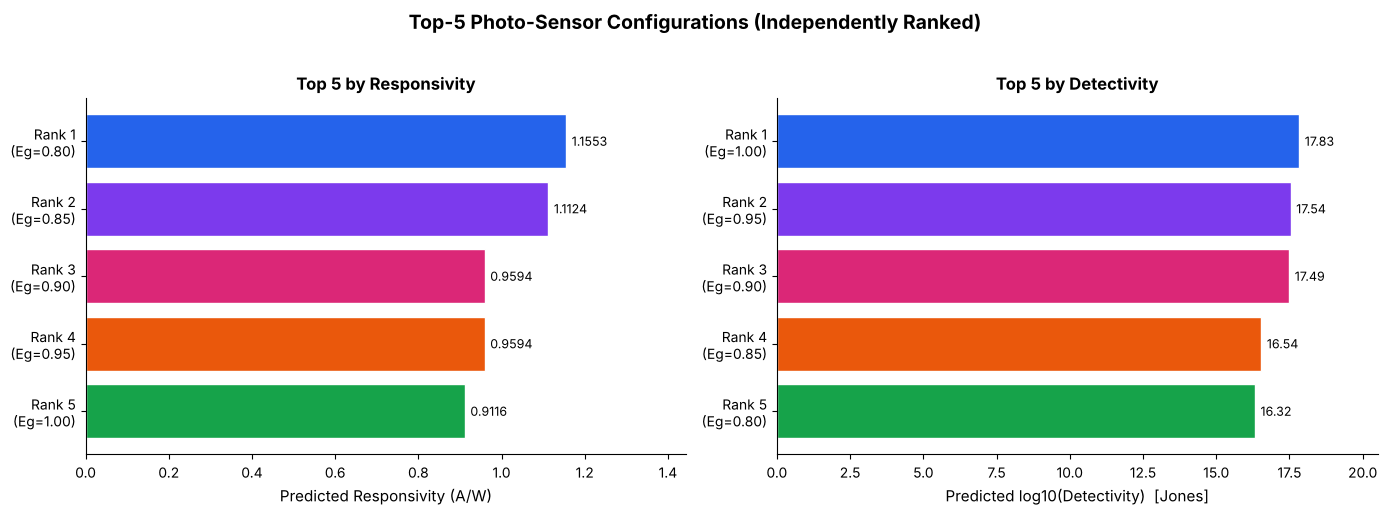

Plot 1 saved: results/plot1_top5_bar.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Top-5 Photo-Sensor Configurations (Independently Ranked)', fontsize=14, fontweight='bold', y=1.02)

ranks  = [f'Rank {i}\n(Eg={eg:.2f})' for i, eg in zip(range(1, 6), top5_R['Eg'].values)]
colors = ['#2563eb', '#7c3aed', '#db2777', '#ea580c', '#16a34a']

ax = axes[0]
bars = ax.barh(ranks[::-1], top5_R['Pred_Responsivity'].values[::-1],
               color=colors[::-1], edgecolor='white')
ax.set_xlabel('Predicted Responsivity (A/W)', fontsize=11)
ax.set_title('Top 5 by Responsivity', fontsize=12, fontweight='bold')
ax.bar_label(bars, fmt='%.4f', padding=4, fontsize=9)
ax.set_xlim(0, top5_R['Pred_Responsivity'].max() * 1.25)
ax.spines[['top', 'right']].set_visible(False)

ranks_D = [f'Rank {i}\n(Eg={eg:.2f})' for i, eg in zip(range(1, 6), top5_D['Eg'].values)]

ax2 = axes[1]
bars2 = ax2.barh(ranks_D[::-1], top5_D['Pred_log10_D'].values[::-1],
                 color=colors[::-1], edgecolor='white')
ax2.set_xlabel('Predicted log10(Detectivity)  [Jones]', fontsize=11)
ax2.set_title('Top 5 by Detectivity', fontsize=12, fontweight='bold')
ax2.bar_label(bars2, fmt='%.2f', padding=4, fontsize=9)
ax2.set_xlim(0, top5_D['Pred_log10_D'].max() * 1.15)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('results/plot1_top5_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 1 saved: results/plot1_top5_bar.png')


### Plot 2 - Feature Importance (Both Models)

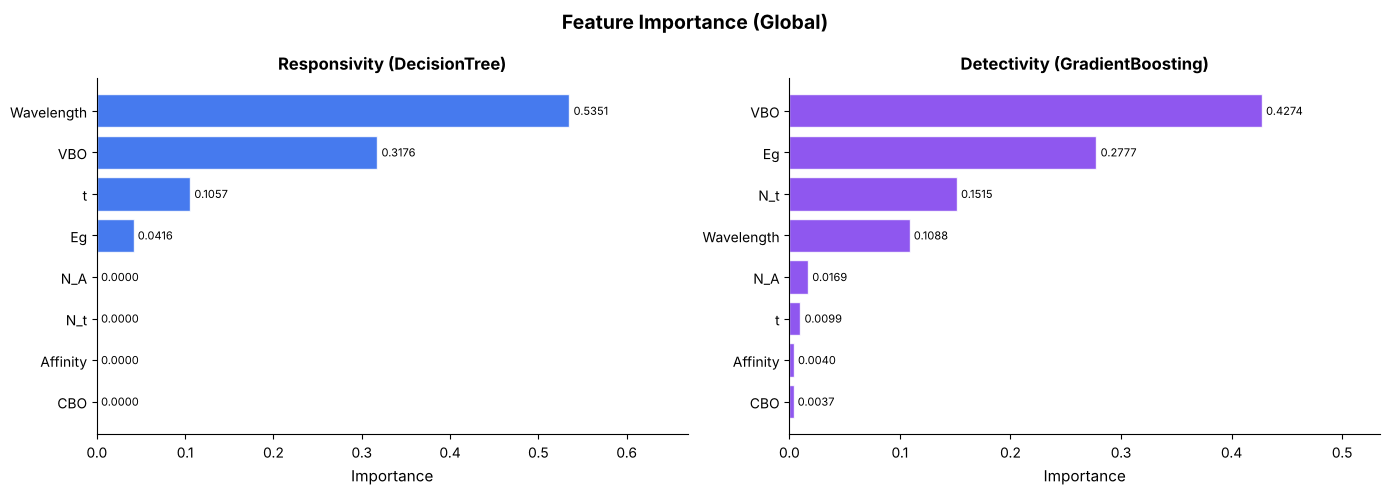

Plot 2 saved: results/plot2_feature_importance.png


In [14]:
fi_R = pd.Series(model_R.feature_importances_, index=FEATURES).sort_values(ascending=True)
fi_D = pd.Series(model_D.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Feature Importance (Global)', fontsize=14, fontweight='bold')

for ax, fi, title, color in zip(
    axes,
    [fi_R, fi_D],
    ['Responsivity (DecisionTree)', 'Detectivity (GradientBoosting)'],
    ['#2563eb', '#7c3aed']
):
    bars = ax.barh(fi.index, fi.values, color=color, alpha=0.85, edgecolor='white')
    ax.set_xlabel('Importance', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
    ax.set_xlim(0, fi.max() * 1.25)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('results/plot2_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 2 saved: results/plot2_feature_importance.png')


### Plot 3 - Per-parameter Response Curves vs. Responsivity (5 sub-plots)

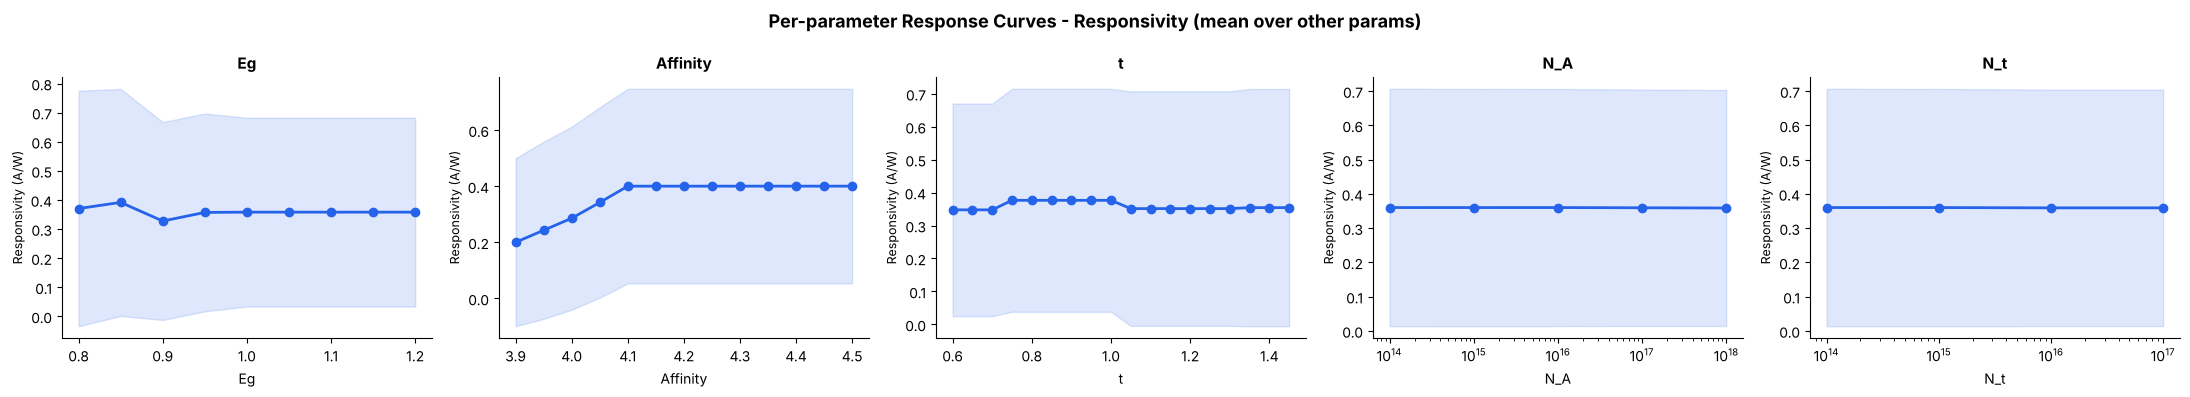

Plot 3 saved: results/plot3_response_curves_R.png


In [15]:
sensitivity_params = ['Eg', 'Affinity', 't', 'N_A', 'N_t']

fig4, axes4 = plt.subplots(1, 5, figsize=(22, 4))
fig4.suptitle('Per-parameter Response Curves - Responsivity (mean over other params)',
              fontsize=13, fontweight='bold')

for ax, param in zip(axes4, sensitivity_params):
    grp = df_results.groupby(param).agg(
        mean_R=('Pred_Responsivity', 'mean'),
        std_R =('Pred_Responsivity', 'std'),
    ).reset_index()
    x = grp[param].values
    ax.plot(x, grp['mean_R'], marker='o', color='#2563eb', linewidth=2, markersize=6)
    ax.fill_between(x,
                    grp['mean_R'] - grp['std_R'],
                    grp['mean_R'] + grp['std_R'],
                    alpha=0.15, color='#2563eb')
    ax.set_xlabel(param, fontsize=10)
    ax.set_ylabel('Responsivity (A/W)', fontsize=9)
    ax.set_title(param, fontsize=11, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    if param in {'N_A', 'N_t'}:
        ax.set_xscale('log')

fig4.tight_layout()
fig4.savefig('results/plot3_response_curves_R.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 3 saved: results/plot3_response_curves_R.png')


### Plot 4 - Per-parameter Response Curves vs. Detectivity (5 sub-plots)

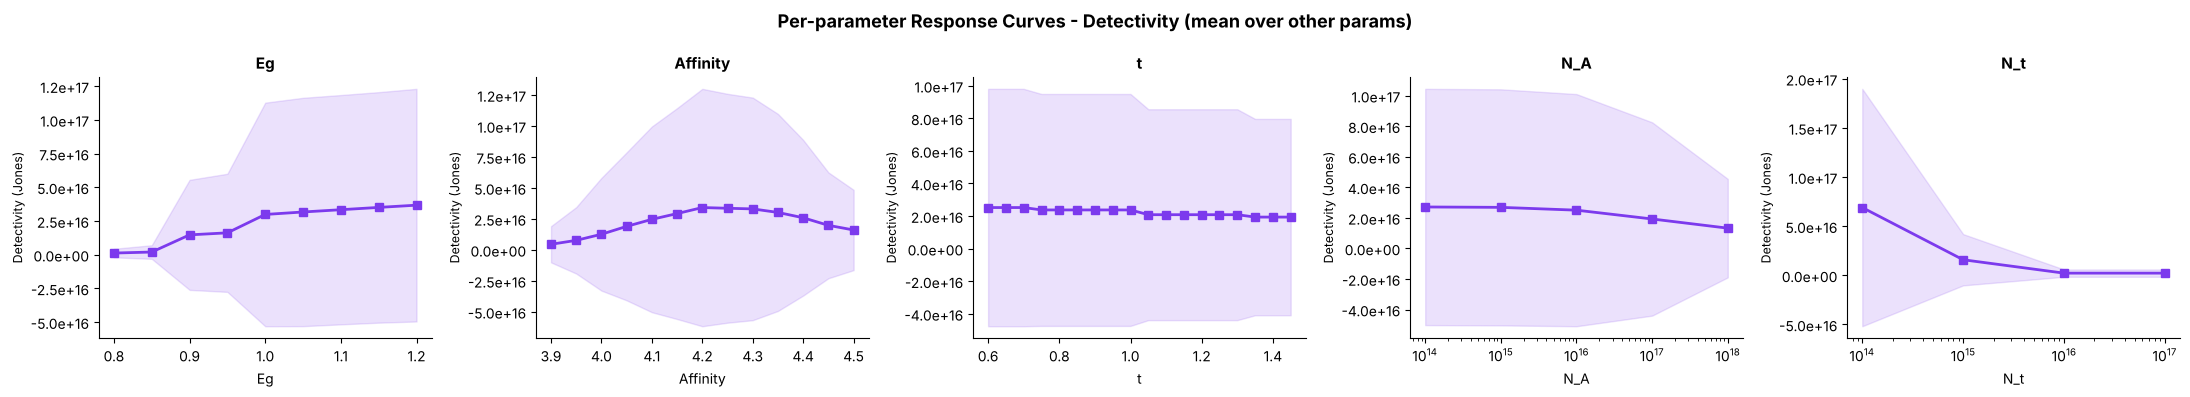

Plot 4 saved: results/plot4_response_curves_D.png


In [16]:
fig5, axes5 = plt.subplots(1, 5, figsize=(22, 4))
fig5.suptitle('Per-parameter Response Curves - Detectivity (mean over other params)',
              fontsize=13, fontweight='bold')

for ax, param in zip(axes5, sensitivity_params):
    grp = df_results.groupby(param).agg(
        mean_D=('Pred_Detectivity', 'mean'),
        std_D =('Pred_Detectivity', 'std'),
    ).reset_index()
    x = grp[param].values
    ax.plot(x, grp['mean_D'], marker='s', color='#7c3aed', linewidth=2, markersize=6)
    ax.fill_between(x,
                    grp['mean_D'] - grp['std_D'],
                    grp['mean_D'] + grp['std_D'],
                    alpha=0.15, color='#7c3aed')
    ax.set_xlabel(param, fontsize=10)
    ax.set_ylabel('Detectivity (Jones)', fontsize=9)
    ax.set_title(param, fontsize=11, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1e'))
    if param in {'N_A', 'N_t'}:
        ax.set_xscale('log')

fig5.tight_layout()
fig5.savefig('results/plot4_response_curves_D.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 4 saved: results/plot4_response_curves_D.png')


## 12. Final Optimized Photo-Sensor Configuration

In [17]:
best_R_row = top5_R.iloc[0]
best_D_row = top5_D.iloc[0]

print()
print('=' * 57)
print('========== BEST RESPONSIVITY CONFIGURATION (Rank 1, R-list) ==========')
print(f'  Eg         = {best_R_row["Eg"]:.2f} eV')
print(f'  Affinity   = {best_R_row["Affinity"]:.2f} eV')
print(f'  t          = {best_R_row["t"]:.2f} um')
print(f'  N_A        = {best_R_row["N_A"]:.2e} cm-3')
print(f'  N_t        = {best_R_row["N_t"]:.2e} cm-3')
print(f'  Wavelength = {best_R_row["Wavelength"]:.0f} nm')
print(f'  CBO        = {best_R_row["CBO"]:.3f} eV')
print(f'  VBO        = {best_R_row["VBO"]:.3f} eV')
print()
print(f'  Predicted Responsivity = {best_R_row["Pred_Responsivity"]:.6f} A/W')
print(f'  Predicted Detectivity  = {best_R_row["Pred_Detectivity"]:.4e} Jones')
print('=========================================================')
print()
print('=' * 57)
print('========== BEST DETECTIVITY CONFIGURATION (Rank 1, D-list) ==========')
print(f'  Eg         = {best_D_row["Eg"]:.2f} eV')
print(f'  Affinity   = {best_D_row["Affinity"]:.2f} eV')
print(f'  t          = {best_D_row["t"]:.2f} um')
print(f'  N_A        = {best_D_row["N_A"]:.2e} cm-3')
print(f'  N_t        = {best_D_row["N_t"]:.2e} cm-3')
print(f'  Wavelength = {best_D_row["Wavelength"]:.0f} nm')
print(f'  CBO        = {best_D_row["CBO"]:.3f} eV')
print(f'  VBO        = {best_D_row["VBO"]:.3f} eV')
print()
print(f'  Predicted Responsivity = {best_D_row["Pred_Responsivity"]:.6f} A/W')
print(f'  Predicted Detectivity  = {best_D_row["Pred_Detectivity"]:.4e} Jones')
print('=========================================================')
print()

print('Top 5 Table (ranked by Responsivity):')
print('-' * 57)
top5_R_print = top5_R[display_cols].copy()
top5_R_print['Pred_Responsivity'] = top5_R_print['Pred_Responsivity'].map('{:.6f}'.format)
top5_R_print['Pred_Detectivity']  = top5_R_print['Pred_Detectivity'].map('{:.4e}'.format)
top5_R_print['N_A'] = top5_R_print['N_A'].map('{:.0e}'.format)
top5_R_print['N_t'] = top5_R_print['N_t'].map('{:.0e}'.format)
print(top5_R_print.to_string())

print()
print('Top 5 Table (ranked by Detectivity):')
print('-' * 57)
top5_D_print = top5_D[display_cols].copy()
top5_D_print['Pred_Responsivity'] = top5_D_print['Pred_Responsivity'].map('{:.6f}'.format)
top5_D_print['Pred_Detectivity']  = top5_D_print['Pred_Detectivity'].map('{:.4e}'.format)
top5_D_print['N_A'] = top5_D_print['N_A'].map('{:.0e}'.format)
top5_D_print['N_t'] = top5_D_print['N_t'].map('{:.0e}'.format)
print(top5_D_print.to_string())



========== BEST RESPONSIVITY CONFIGURATION (Rank 1, R-list) ==========
  Eg         = 0.80 eV
  Affinity   = 4.10 eV
  t          = 1.35 um
  N_A        = 1.00e+16 cm-3
  N_t        = 1.00e+14 cm-3
  Wavelength = 1480 nm
  CBO        = 0.010 eV
  VBO        = 0.520 eV

  Predicted Responsivity = 1.155336 A/W
  Predicted Detectivity  = 4.4849e+15 Jones

========== BEST DETECTIVITY CONFIGURATION (Rank 1, D-list) ==========
  Eg         = 1.00 eV
  Affinity   = 4.30 eV
  t          = 0.75 um
  N_A        = 1.00e+14 cm-3
  N_t        = 1.00e+14 cm-3
  Wavelength = 1080 nm
  CBO        = 0.210 eV
  VBO        = 0.120 eV

  Predicted Responsivity = 0.830494 A/W
  Predicted Detectivity  = 6.8078e+17 Jones

Top 5 Table (ranked by Responsivity):
---------------------------------------------------------
        Eg  Affinity     t    N_A    N_t  Wavelength   CBO   VBO Pred_Responsivity Pred_Detectivity
Rank                                                                                          

## 13. SHAP explanation of the optimized device and SHAP-derived design rules

Exact TreeSHAP is applied to the two final models (DT for $R$, GB for $\log_{10}D^*$) to explain

* **(a) the ML-optimized high-$R$ / high-$D^*$ device** (Rank 1 of the constrained search, Section 9), and
* **(b) a low-performance counterpart**: the candidate of the same fixed Ca$_2$CdAs$_2$ absorber (Section 9 constraints) with the
  lowest combined score at the same wavelength, so that the comparison isolates the design parameters ($t$, $N_A$, $N_t$),

as SHAP waterfall plots (both at the optimized device's wavelength). Each bar is the contribution of one input to the prediction relative to the model's expected value
$E[f(X)]$. A level-wise SHAP analysis on an in-domain sample of the grid then turns the trends into device design rules.

*In-domain* means grid points inside the SCAPS training ranges ($E_g \le 1.0$ eV, $\chi_{Abs} \ge 4.0$ eV, $t \le 1.4$ µm, $N_A \ge 10^{14}$,
$N_t \le 10^{16}$ cm$^{-3}$) and, for the design rules, inside each candidate's absorption window ($\lambda \le hc/E_g$),
so that the rules are not driven by tree-model extrapolation or by the sub-bandgap region where the response vanishes.

In [18]:
import gc
import shap
import matplotlib as mpl

FEATURE_LABELS = {"Eg": r"$E_g$", "Affinity": r"$\chi_{\mathrm{Abs}}$", "t": r"$t$", "N_A": r"$N_A$",
                  "N_t": r"$N_t$", "Wavelength": r"$\lambda$", "CBO": r"$\mathrm{CBO}$", "VBO": r"$\mathrm{VBO}$"}
MODELS = {"Responsivity": model_R, "log10(Detectivity)": model_D}
ADDITIVITY_TOLERANCE = 1e-6

# Training ranges of the SCAPS dataset (used to flag in-domain grid points)
in_domain = (
    (df_results["Eg"] <= 1.0 + 1e-9) & (df_results["Affinity"] >= 4.0 - 1e-9) & (df_results["t"] <= 1.4 + 1e-9)
    & (df_results["N_A"] >= 1e14 * (1 - 1e-9)) & (df_results["N_t"] <= 1e16 * (1 + 1e-9))
)
print(f"In-domain grid points: {in_domain.sum():,} / {len(df_results):,}")

# (a) ML-optimized device = reported design of the constrained search (Section 9)
device_high = best_c

# (b) low-performance counterpart = lowest combined score among the candidates of the same fixed absorber
#     (Section 9 constraints) at the same wavelength. The stable sort keeps grid order among tied candidates,
#     so a plateau of equal scores resolves to its thinnest absorber (reproducible choice).
same_lambda = df_constrained[np.isclose(df_constrained["Wavelength"], device_high["Wavelength"])]
device_low = same_lambda.sort_values("Combined_Score", ascending=True, kind="stable").iloc[0]
n_low_tied = int(np.isclose(same_lambda["Combined_Score"], device_low["Combined_Score"]).sum())
print(f"Low-performance candidates sharing the lowest score: {n_low_tied}")

summary = pd.DataFrame([device_high, device_low], index=["Optimized (high R, high D*)", "Low-performance counterpart"])
display(summary[FEATURES + ["Pred_Responsivity", "Pred_Detectivity", "Combined_Score"]])

In-domain grid points: 1,206,150 / 3,622,320
Low-performance candidates sharing the lowest score: 3


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO,Pred_Responsivity,Pred_Detectivity,Combined_Score
"Optimized (high R, high D*)",1.0,4.2,1.35,1.000000e+15,1.000000e+14,1160.0,0.11,0.22,0.911404,4.596433e+17,0.889650
Low-performance counterpart,1.0,4.1,0.60,1.000000e+16,1.000000e+16,1160.0,0.01,0.32,0.741384,4.707375e+15,0.760284


Saved: results/SHAP_Waterfall_Optimized_Responsivity.tiff


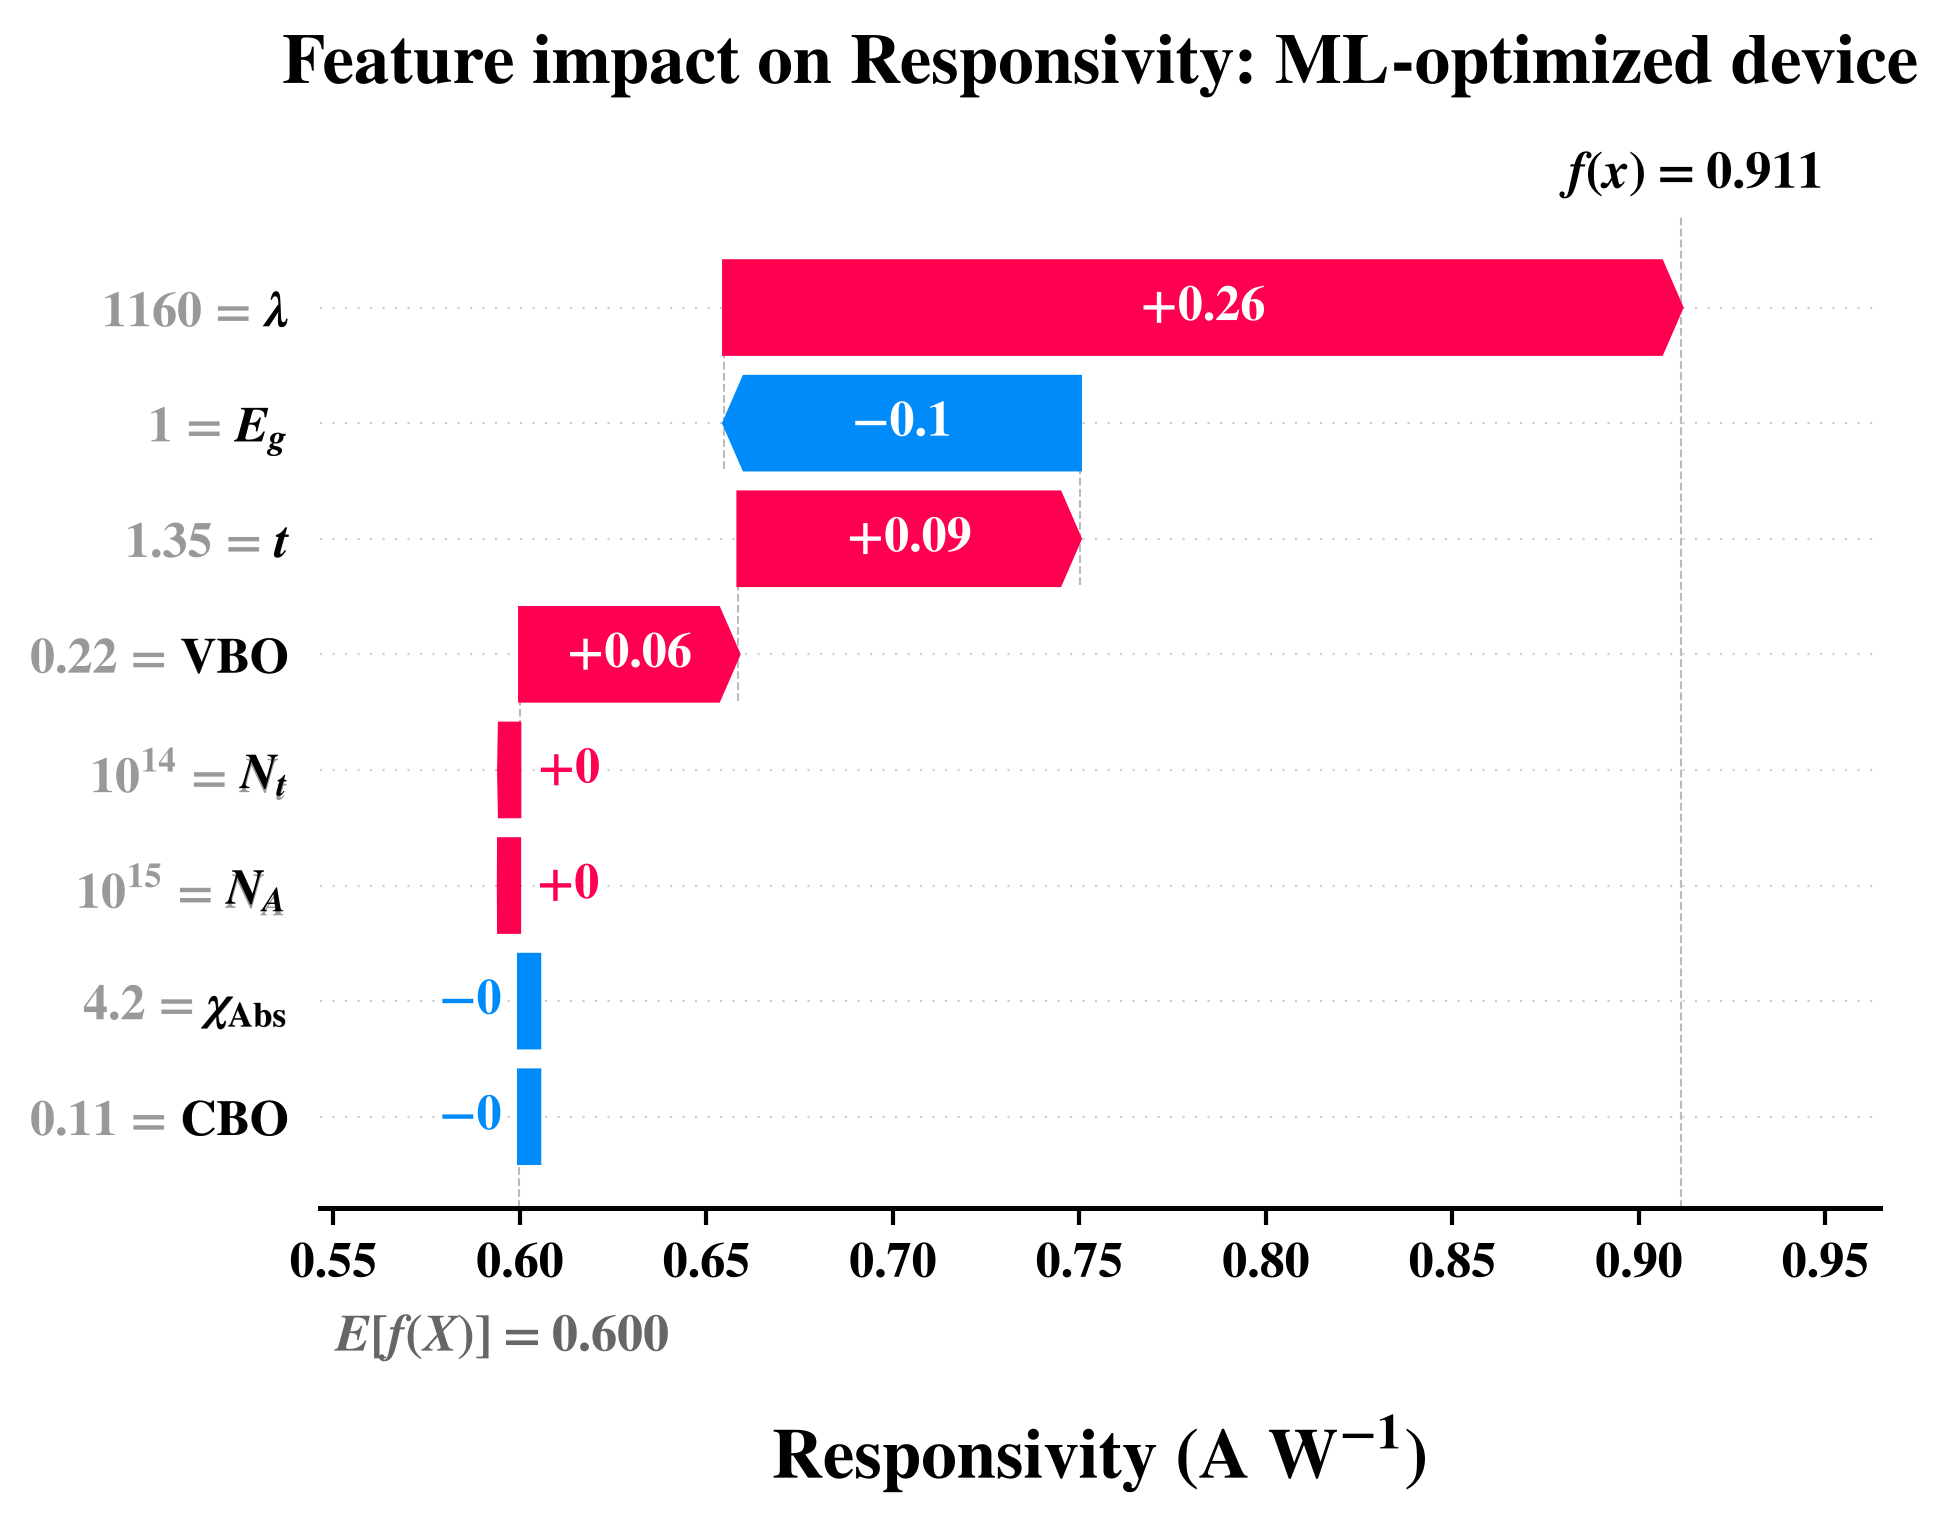

Feature impact on Responsivity: ML-optimized device: E[f(X)] = 0.5998, f(x) = 0.9114, additivity error = 4.0e-15


Saved: results/SHAP_Waterfall_Optimized_log10_Detectivity.tiff


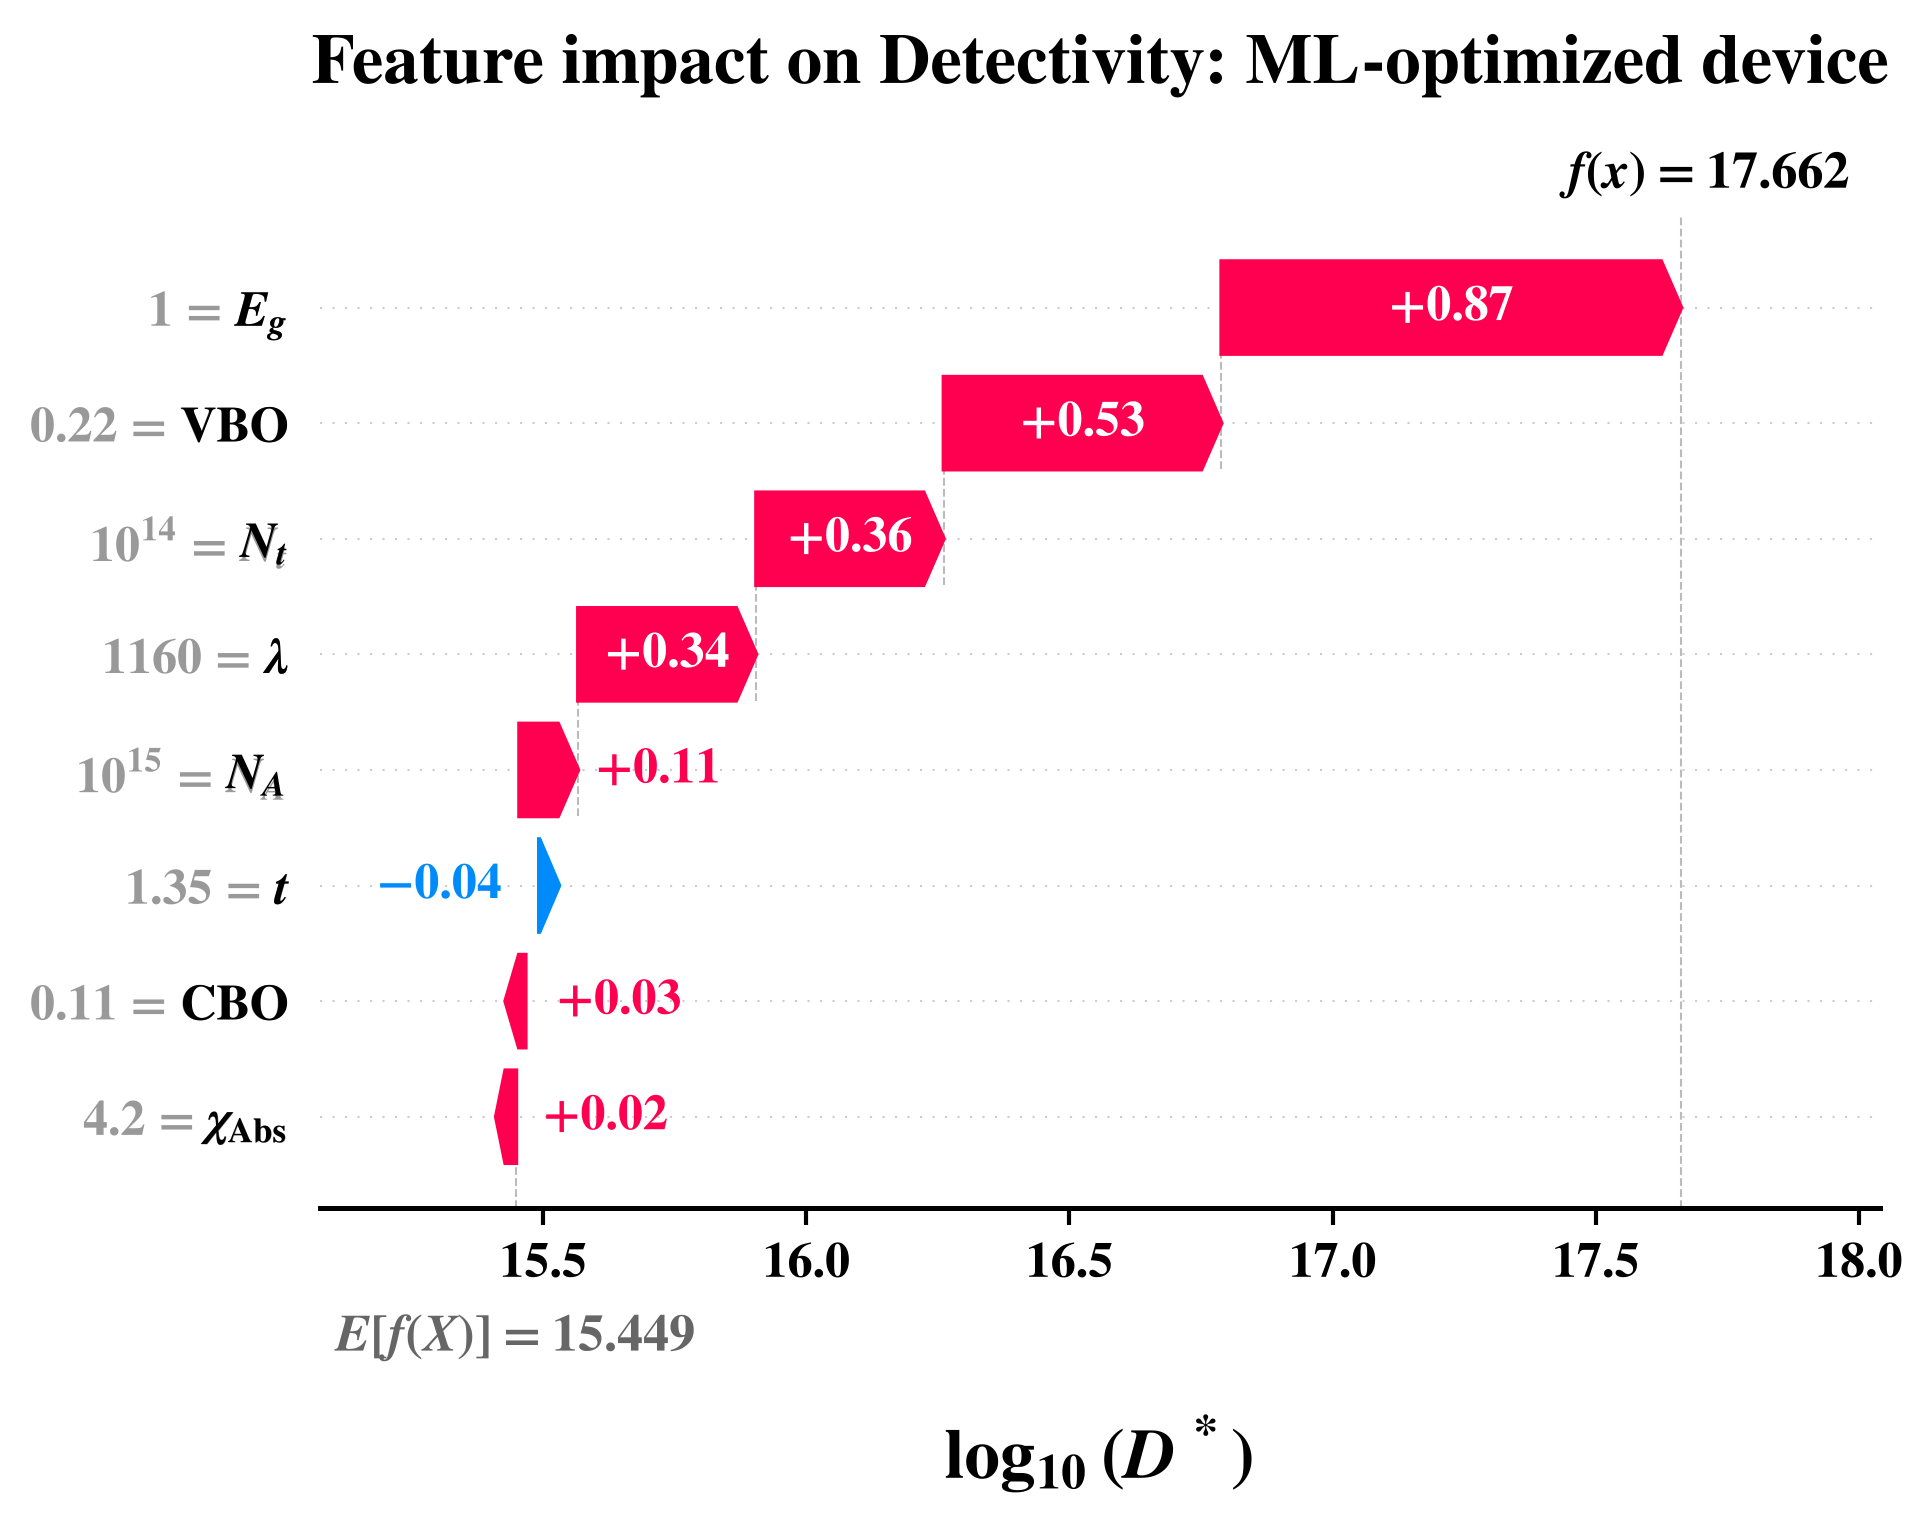

Feature impact on Detectivity: ML-optimized device: E[f(X)] = 15.4486, f(x) = 17.6624, additivity error = 1.8e-14


Saved: results/SHAP_Waterfall_LowPerformance_Responsivity.tiff


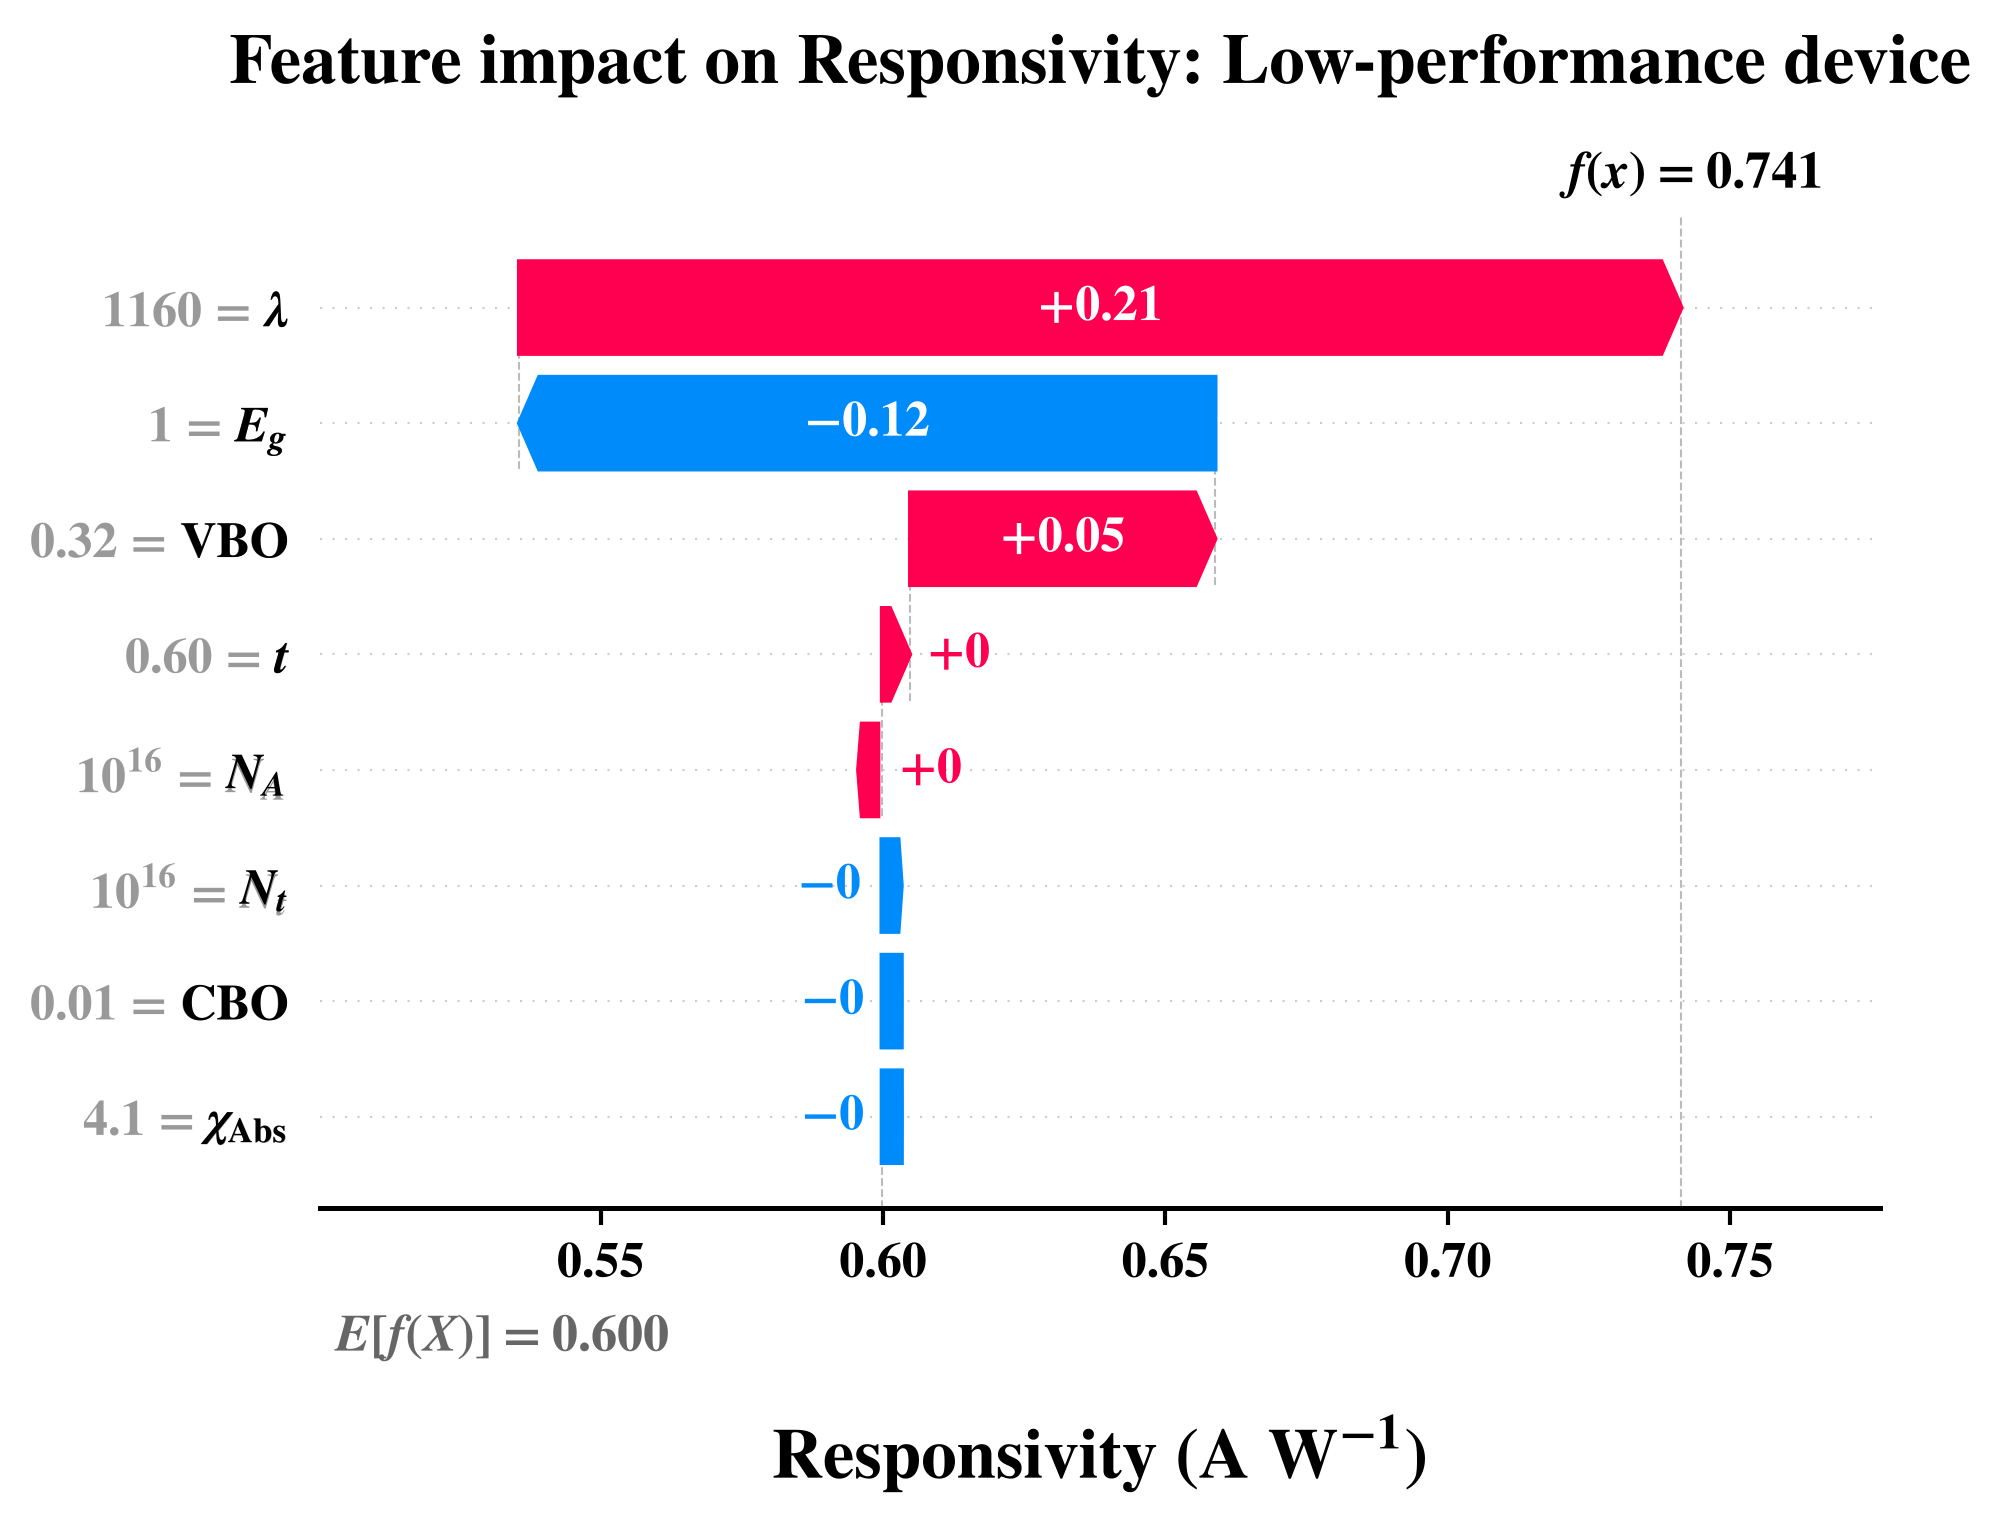

Feature impact on Responsivity: Low-performance device: E[f(X)] = 0.5998, f(x) = 0.7414, additivity error = 6.9e-15


Saved: results/SHAP_Waterfall_LowPerformance_log10_Detectivity.tiff


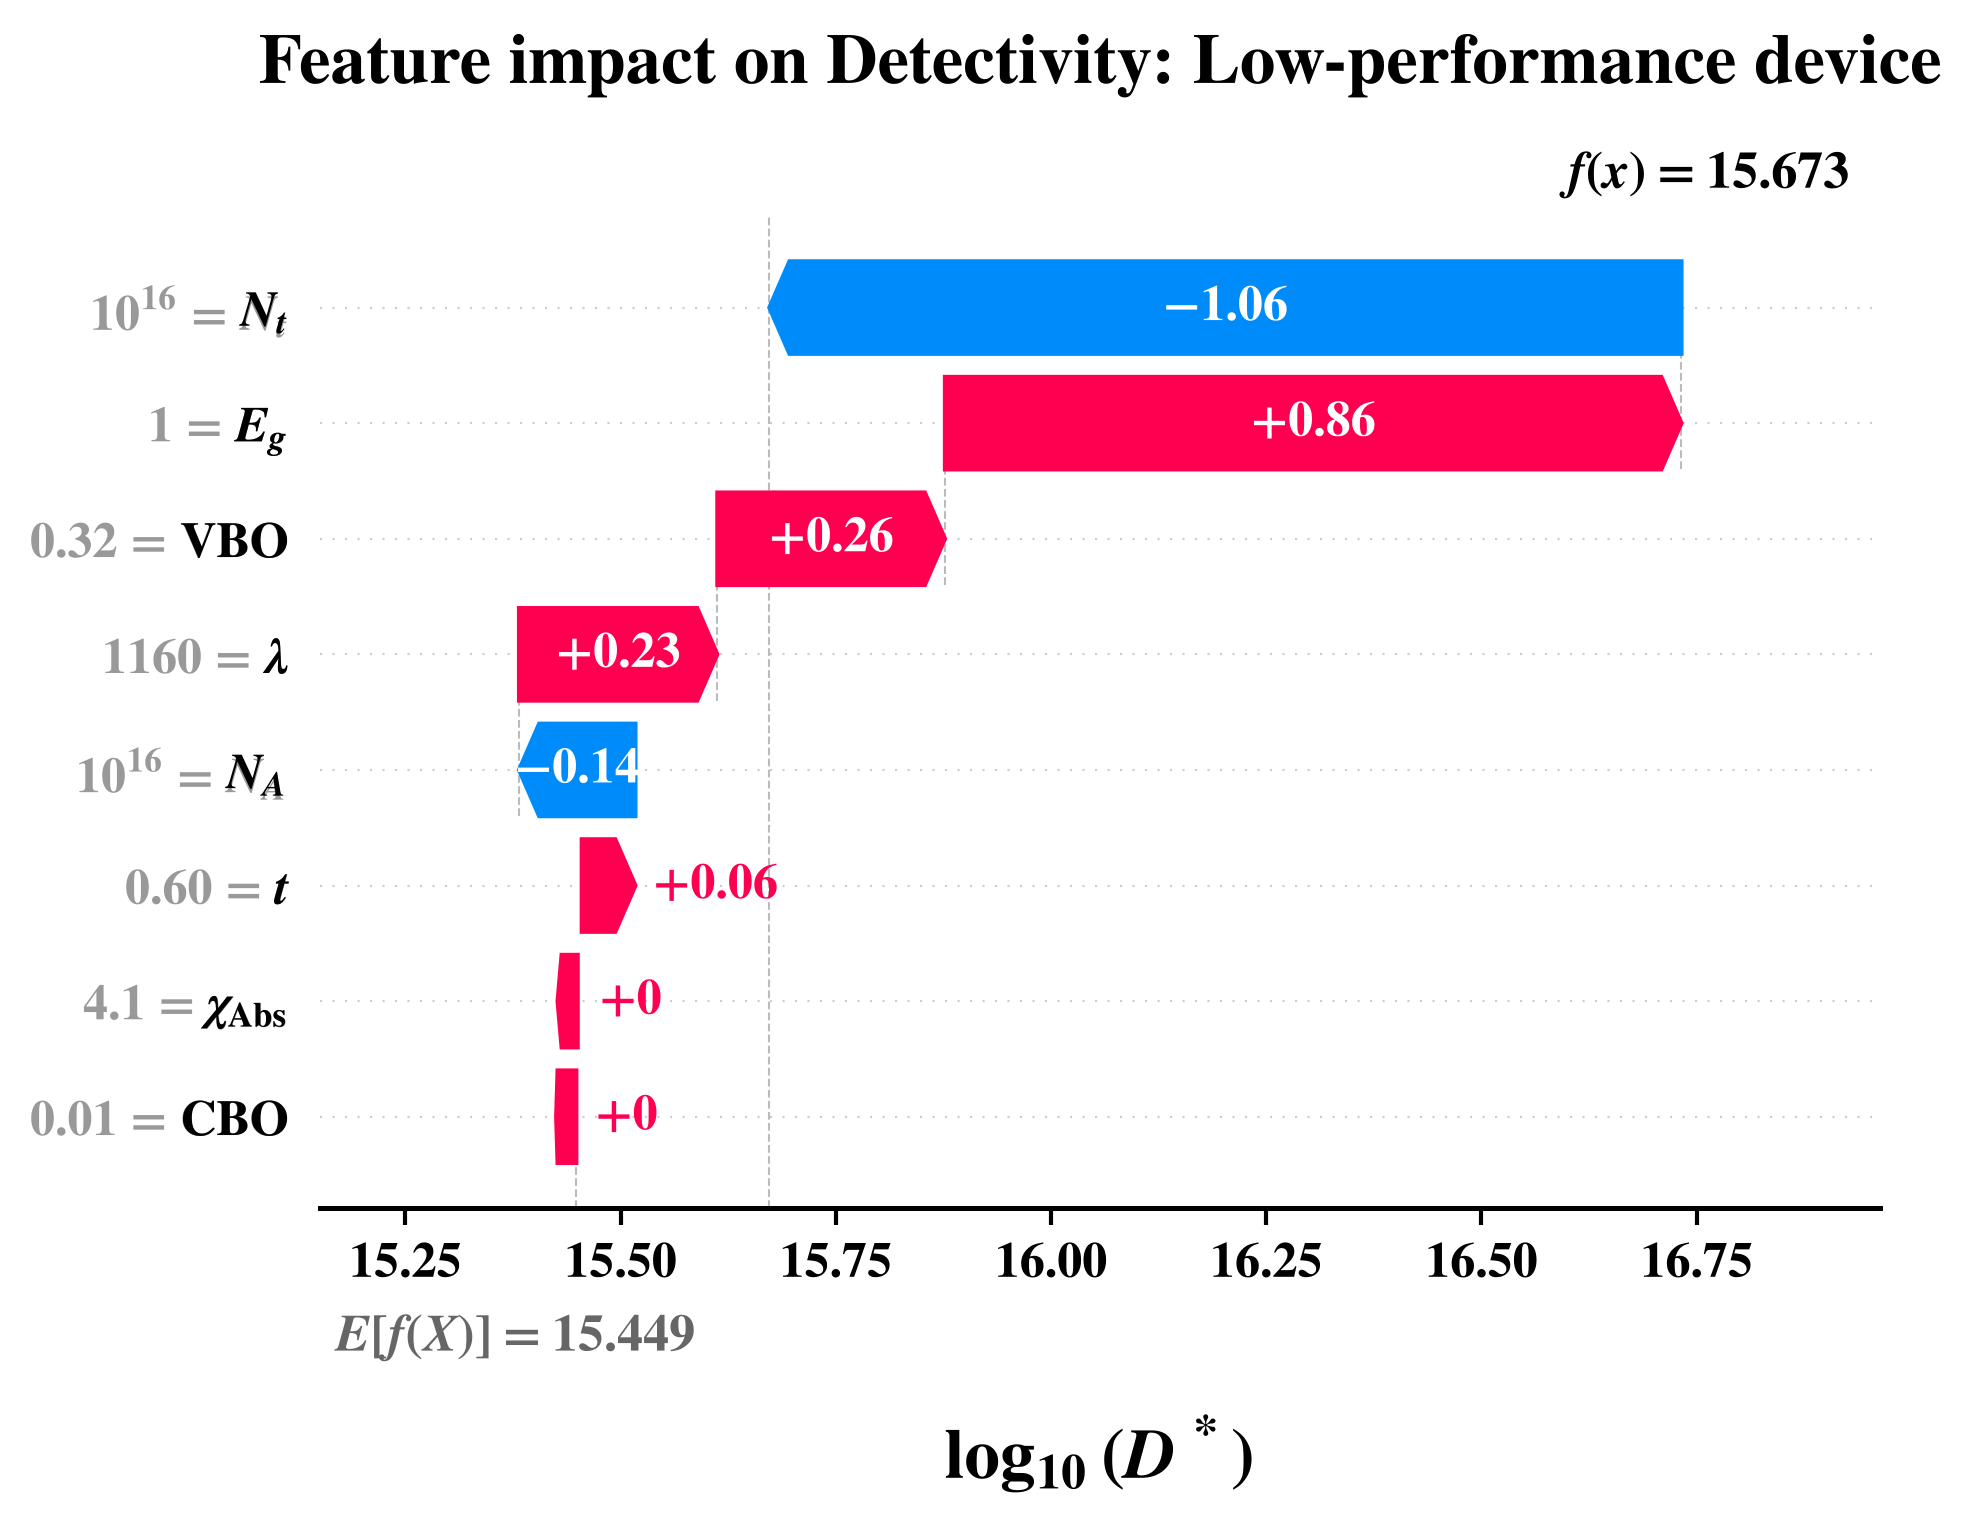

Feature impact on Detectivity: Low-performance device: E[f(X)] = 15.4486, f(x) = 15.6728, additivity error = 1.1e-14

SHAP contributions (rows: device / target, columns: input):


,Eg,Affinity,t,N_A,N_t,Wavelength,CBO,VBO
Optimized_R,-0.0954,-0.0000,0.0915,0.0001,0.0002,0.2567,-0.0000,0.0585
Optimized_D,0.8736,0.0178,-0.0375,0.1118,0.3562,0.3385,0.0258,0.5278
LowPerformance_R,-0.1233,-0.0000,0.0050,0.0006,-0.0006,0.2058,-0.0000,0.0541
LowPerformance_D,0.8555,0.0047,0.0624,-0.1352,-1.0595,0.2304,0.0016,0.2644


In [19]:
mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 13, "font.weight": "bold", "axes.labelsize": 17,
    "axes.labelweight": "bold", "axes.titlesize": 17, "axes.titleweight": "bold",
    "xtick.labelsize": 12, "ytick.labelsize": 14, "axes.linewidth": 1.2,
})


def format_feature_value(feature, value):
    value = float(value)
    if feature in {"N_A", "N_t"}:
        exponent = int(np.floor(np.log10(abs(value))))
        mantissa = value / 10.0 ** exponent
        if np.isclose(abs(mantissa), 1.0, rtol=1e-3, atol=1e-8):
            return rf"$10^{{{exponent}}}$"
        return rf"${mantissa:.2f}\times10^{{{exponent}}}$"
    if feature == "Wavelength":
        return rf"${value:.0f}$"
    if feature == "t":
        return rf"${value:.2f}$"
    return rf"${f'{value:.2f}'.rstrip('0').rstrip('.')}$"


def save_tiff(fig, filename):
    path = os.path.join("results", filename)
    try:
        fig.savefig(path, dpi=600, bbox_inches="tight", format="tiff", pil_kwargs={"compression": "tiff_lzw"})
    except TypeError:
        fig.savefig(path, dpi=600, bbox_inches="tight", format="tiff")
    print(f"Saved: {path}")


def exact_shap_row(model, row):
    x_single = pd.DataFrame([row[FEATURES].to_numpy(dtype=float)], columns=FEATURES)
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent", model_output="raw")
    values = np.asarray(explainer.shap_values(x_single, approximate=False, check_additivity=True))
    values = values[0] if values.ndim == 2 else values[0, :, 0]
    expected = float(np.asarray(explainer.expected_value).reshape(-1)[0])
    predicted = float(model.predict(x_single)[0])
    error = abs(predicted - (expected + values.sum()))
    if error > ADDITIVITY_TOLERANCE:
        raise RuntimeError(f"SHAP additivity failed: {error:.3e}")
    return x_single, values, expected, predicted, error


def plot_waterfall(model, row, title, xlabel, filename):
    x_single, shap_row, expected, predicted, error = exact_shap_row(model, row)
    display_values = np.array([format_feature_value(f, row[f]) for f in FEATURES], dtype=object)
    explanation = shap.Explanation(values=shap_row, base_values=expected, data=x_single.iloc[0].to_numpy(),
                                   display_data=display_values, feature_names=[FEATURE_LABELS[f] for f in FEATURES])
    explanation.display_data = display_values

    plt.figure(figsize=(8.0, 5.7), dpi=300)
    shap.plots.waterfall(explanation, max_display=len(FEATURES), show=False)
    fig = plt.gcf(); ax = fig.axes[0]
    for extra_ax in fig.axes[1:]:
        extra_ax.set_visible(False)
    for text in ax.texts:
        if "f(x)" in text.get_text() or "E[f(X)]" in text.get_text():
            text.set_visible(False)
    ax.set_title(title, fontsize=17, fontweight="bold", pad=32)
    ax.set_xlabel(xlabel, fontsize=17, fontweight="bold", labelpad=30)
    ax.text(0.80, 1.015, rf"$f(x)={predicted:.3f}$", transform=ax.transAxes, fontsize=12.5, fontweight="bold",
            ha="left", va="bottom", clip_on=False)
    ax.text(0.01, -0.105, rf"$E[f(X)]={expected:.3f}$", transform=ax.transAxes, fontsize=12.5, fontweight="bold",
            color="#666666", ha="left", va="top", clip_on=False)
    for axis in fig.axes:
        axis.tick_params(axis="both", which="major", labelsize=12, width=1.0, length=4)
        for label in axis.get_xticklabels() + axis.get_yticklabels():
            label.set_fontfamily("serif"); label.set_fontweight("bold")
        for text in axis.texts:
            if text.get_visible():
                text.set_fontfamily("serif"); text.set_fontweight("bold")
    fig.set_size_inches(8.0, 5.7)
    fig.subplots_adjust(left=0.33, right=0.98, bottom=0.22, top=0.80)
    save_tiff(fig, filename)
    plt.show(); plt.close(fig); gc.collect()

    print(f"{title}: E[f(X)] = {expected:.4f}, f(x) = {predicted:.4f}, additivity error = {error:.1e}")
    return pd.Series(shap_row, index=FEATURES, name=title)


waterfall_records = {}
for tag, device in [("Optimized", device_high), ("LowPerformance", device_low)]:
    label = "ML-optimized device" if tag == "Optimized" else "Low-performance device"
    waterfall_records[f"{tag}_R"] = plot_waterfall(
        model_R, device, f"Feature impact on Responsivity: {label}", r"Responsivity (A W$^{-1}$)",
        f"SHAP_Waterfall_{tag}_Responsivity.tiff")
    waterfall_records[f"{tag}_D"] = plot_waterfall(
        model_D, device, f"Feature impact on Detectivity: {label}", r"$\log_{10}(D^*)$",
        f"SHAP_Waterfall_{tag}_log10_Detectivity.tiff")

waterfall_table = pd.DataFrame(waterfall_records).T
waterfall_table.to_csv("results/SHAP_Waterfall_Contributions.csv")
print("\nSHAP contributions (rows: device / target, columns: input):")
display(waterfall_table.round(4))

### 13.1 SHAP-derived design rules

For each swept parameter, the mean SHAP value at every discrete level is computed on a balanced in-domain sample of the
grid (the level with the highest mean SHAP is the one the model associates with the best performance). The trend over the
levels is classified as increasing, decreasing or non-monotonic, and the two targets are compared to flag trade-offs.

In [20]:
SAMPLE_PER_LEVEL = 400          # rows drawn per level of each parameter
RNG = np.random.default_rng(42)

# Restrict to the absorption window of each candidate (photon energy above the bandgap, λ ≤ hc/Eg)
in_band = df_results["Wavelength"] <= 1239.84 / df_results["Eg"]
domain_df = df_results[in_domain & in_band].reset_index(drop=True)
print(f"In-domain grid points inside the absorption window: {len(domain_df):,}")
sample_idx = RNG.choice(len(domain_df), size=min(20000, len(domain_df)), replace=False)
sample_df = domain_df.iloc[sample_idx].reset_index(drop=True)
X_sample = sample_df[FEATURES].astype(float)

shap_sample = {}
for target, model in MODELS.items():
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent", model_output="raw")
    values = np.asarray(explainer.shap_values(X_sample, approximate=False, check_additivity=False))
    shap_sample[target] = pd.DataFrame(values if values.ndim == 2 else values[:, :, 0], columns=FEATURES)
    del explainer
print(f"SHAP computed on {len(X_sample):,} in-domain grid rows for both targets.")

DESIGN_PARAMS = ["Eg", "Affinity", "CBO", "VBO", "t", "N_A", "N_t", "Wavelength"]
UNITS = {"Eg": "eV", "Affinity": "eV", "CBO": "eV", "VBO": "eV", "t": "µm", "N_A": "cm⁻³", "N_t": "cm⁻³", "Wavelength": "nm"}
UNITS_TEX = {"Eg": "eV", "Affinity": "eV", "CBO": "eV", "VBO": "eV", "t": r"$\mu$m", "N_A": r"cm$^{-3}$", "N_t": r"cm$^{-3}$", "Wavelength": "nm"}


def fmt_level(p, v):
    return f"{v:.0e}" if p in {"N_A", "N_t"} else (f"{v:.0f}" if p == "Wavelength" else f"{v:g}")


def trend_label(levels, means, negligible_below):
    peak = levels[int(np.argmax(means))]
    if means.max() - means.min() < negligible_below:
        return "negligible", peak
    rho = pd.Series(means).corr(pd.Series(np.log10(levels) if max(levels) / max(min(levels), 1e-30) > 100 else levels),
                                method="spearman")
    if rho >= 0.6:   return "increases with parameter", peak
    if rho <= -0.6:  return "decreases with parameter", peak
    return "non-monotonic", peak


# A parameter whose level-to-level SHAP range is below 5 % of the largest range for that target is called negligible
NEGLIGIBLE = {}
for target in MODELS:
    ranges = []
    for p in ["Eg", "Affinity", "CBO", "VBO", "t", "N_A", "N_t", "Wavelength"]:
        levels = np.sort(sample_df[p].round(4).unique())
        means = np.array([shap_sample[target].loc[np.isclose(sample_df[p], lv), p].mean() for lv in levels])
        ranges.append(means.max() - means.min())
    NEGLIGIBLE[target] = 0.05 * max(ranges)


rule_rows, level_rows = [], []
for p in DESIGN_PARAMS:
    levels = np.sort(sample_df[p].round(4).unique())
    entry = {"Parameter": p, "Unit": UNITS[p]}
    trends = {}
    for target, short in [("Responsivity", "R"), ("log10(Detectivity)", "D")]:
        means = np.array([shap_sample[target].loc[np.isclose(sample_df[p], lv), p].mean() for lv in levels])
        for lv, m in zip(levels, means):
            level_rows.append({"Parameter": p, "Level": lv, "Target": target, "Mean_SHAP": m,
                               "N": int(np.isclose(sample_df[p], lv).sum())})
        trend, peak = trend_label(levels, means, NEGLIGIBLE[target])
        trends[short] = trend
        entry[f"Best level ({short})"] = fmt_level(p, peak)
        entry[f"SHAP range ({short})"] = f"{means.min():+.3f} to {means.max():+.3f}"
        entry[f"Trend ({short})"] = trend
    directional = {"increases with parameter", "decreases with parameter"}
    if {trends["R"], trends["D"]} == directional:
        entry["Trade-off"] = "Yes"
    elif trends["R"] == trends["D"] or "negligible" in (trends["R"], trends["D"]):
        entry["Trade-off"] = "No"
    else:
        entry["Trade-off"] = "Partial"
    rule_rows.append(entry)

design_rules = pd.DataFrame(rule_rows)
level_shap = pd.DataFrame(level_rows)
design_rules.to_csv("results/SHAP_Design_Rules.csv", index=False)
level_shap.to_csv("results/SHAP_Level_Means.csv", index=False)

print("Mean SHAP per parameter level (in-domain, in-band grid sample):")
with pd.option_context("display.max_rows", 200):
    display(level_shap[level_shap["Parameter"] != "Wavelength"]
            .pivot_table(index=["Parameter", "Level"], columns="Target", values="Mean_SHAP").round(4))
print("\nSHAP-derived design rules:")
display(design_rules)

In-domain grid points inside the absorption window: 765,765


SHAP computed on 20,000 in-domain grid rows for both targets.
Mean SHAP per parameter level (in-domain, in-band grid sample):


Target                   Responsivity  log10(Detectivity)
Parameter Level                                          
Affinity   4.000000e+00       -0.0000             -0.0201
           4.050000e+00       -0.0000              0.0133
           4.100000e+00       -0.0000              0.0097
           4.150000e+00       -0.0000              0.0178
           4.200000e+00       -0.0000              0.0112
           4.250000e+00       -0.0000              0.0083
           4.300000e+00        0.0000              0.0143
           4.350000e+00        0.0000              0.0141
           4.400000e+00        0.0000              0.0140
           4.450000e+00        0.0000              0.0141
           4.500000e+00        0.0000             -0.0069
CBO       -9.000000e-02       -0.0000             -0.0268
          -4.000000e-02       -0.0000              0.0165
           1.000000e-02       -0.0000              0.0171
           6.000000e-02       -0.0000              0.0085
           1.100000e-01       -0.0000              0.0167
           1.600000e-01       -0.0000              0.0125
           2.100000e-01       -0.0000              0.0148
           2.600000e-01        0.0000              0.0149
           3.100000e-01        0.0000              0.0154
           3.600000e-01        0.0000             -0.0007
           4.100000e-01        0.0000             -0.0000
Eg         8.000000e-01        0.0088              0.1644
           8.500000e-01        0.0010              0.1554
           9.000000e-01       -0.0990              0.5501
           9.500000e-01       -0.0705              0.7439
           1.000000e+00       -0.0823              0.8625
N_A        1.000000e+14        0.0003              0.1217
           1.000000e+15        0.0002              0.1069
           1.000000e+16        0.0002             -0.0280
           1.000000e+17       -0.0000             -0.1046
           1.000000e+18       -0.0004             -0.1127
N_t        1.000000e+14        0.0002              0.3239
           1.000000e+15        0.0002             -0.2531
           1.000000e+16       -0.0009             -1.0369
VBO       -8.000000e-02        0.0471              0.3687
          -3.000000e-02        0.0470              0.3695
           2.000000e-02        0.0472              0.4399
           7.000000e-02        0.0490              0.4204
           1.200000e-01        0.0500              0.4164
           1.700000e-01        0.0496              0.3980
           2.200000e-01        0.0499              0.3884
           2.700000e-01        0.0501              0.3354
           3.200000e-01        0.0495              0.2776
           3.700000e-01        0.0497              0.1278
           4.200000e-01        0.0501              0.0126
           4.700000e-01        0.0506             -0.0552
           5.200000e-01        0.0513             -0.0924
           5.700000e-01       -0.6053             -2.7216
           6.200000e-01       -0.6217             -2.6981
t          6.000000e-01        0.0120              0.0414
           6.500000e-01        0.0118              0.0416
           7.000000e-01        0.0119              0.0418
           7.500000e-01        0.0318             -0.0017
           8.000000e-01        0.0316             -0.0053
           8.500000e-01        0.0321             -0.0043
           9.000000e-01        0.0309             -0.0052
           9.500000e-01        0.0313             -0.0113
           1.000000e+00        0.0313             -0.0098
           1.050000e+00        0.0430             -0.0878
           1.100000e+00        0.0436             -0.0888
           1.150000e+00        0.0426             -0.0870
           1.200000e+00        0.0424             -0.0907
           1.250000e+00        0.0430             -0.0877
           1.300000e+00        0.0416             -0.0888
           1.350000e+00        0.0476             -0.1144
           1.400000e+00        0.0462             -0.115


SHAP-derived design rules:


,Parameter,Unit,Best level (R),SHAP range (R),Trend (R),Best level (D),SHAP range (D),Trend (D),Trade-off
0,Eg,eV,0.8,-0.099 to +0.009,decreases with parameter,1,+0.155 to +0.863,increases with parameter,Yes
1,Affinity,eV,4.5,-0.000 to +0.000,negligible,4.15,-0.020 to +0.018,negligible,No
2,CBO,eV,0.41,-0.000 to +0.000,negligible,0.01,-0.027 to +0.017,negligible,No
3,VBO,eV,0.52,-0.622 to +0.051,non-monotonic,0.02,-2.722 to +0.440,decreases with parameter,Partial
4,t,µm,1.35,+0.012 to +0.048,increases with parameter,0.7,-0.115 to +0.042,negligible,No
5,N_A,cm⁻³,1e+14,-0.000 to +0.000,negligible,1e+14,-0.113 to +0.122,decreases with parameter,No
6,N_t,cm⁻³,1e+14,-0.001 to +0.000,negligible,1e+14,-1.037 to +0.324,decreases with parameter,No
7,Wavelength,nm,1480,-0.359 to +0.306,increases with parameter,1180,-4.202 to +0.204,non-monotonic,Partial


Saved: results/SHAP_Level_Trends.tiff


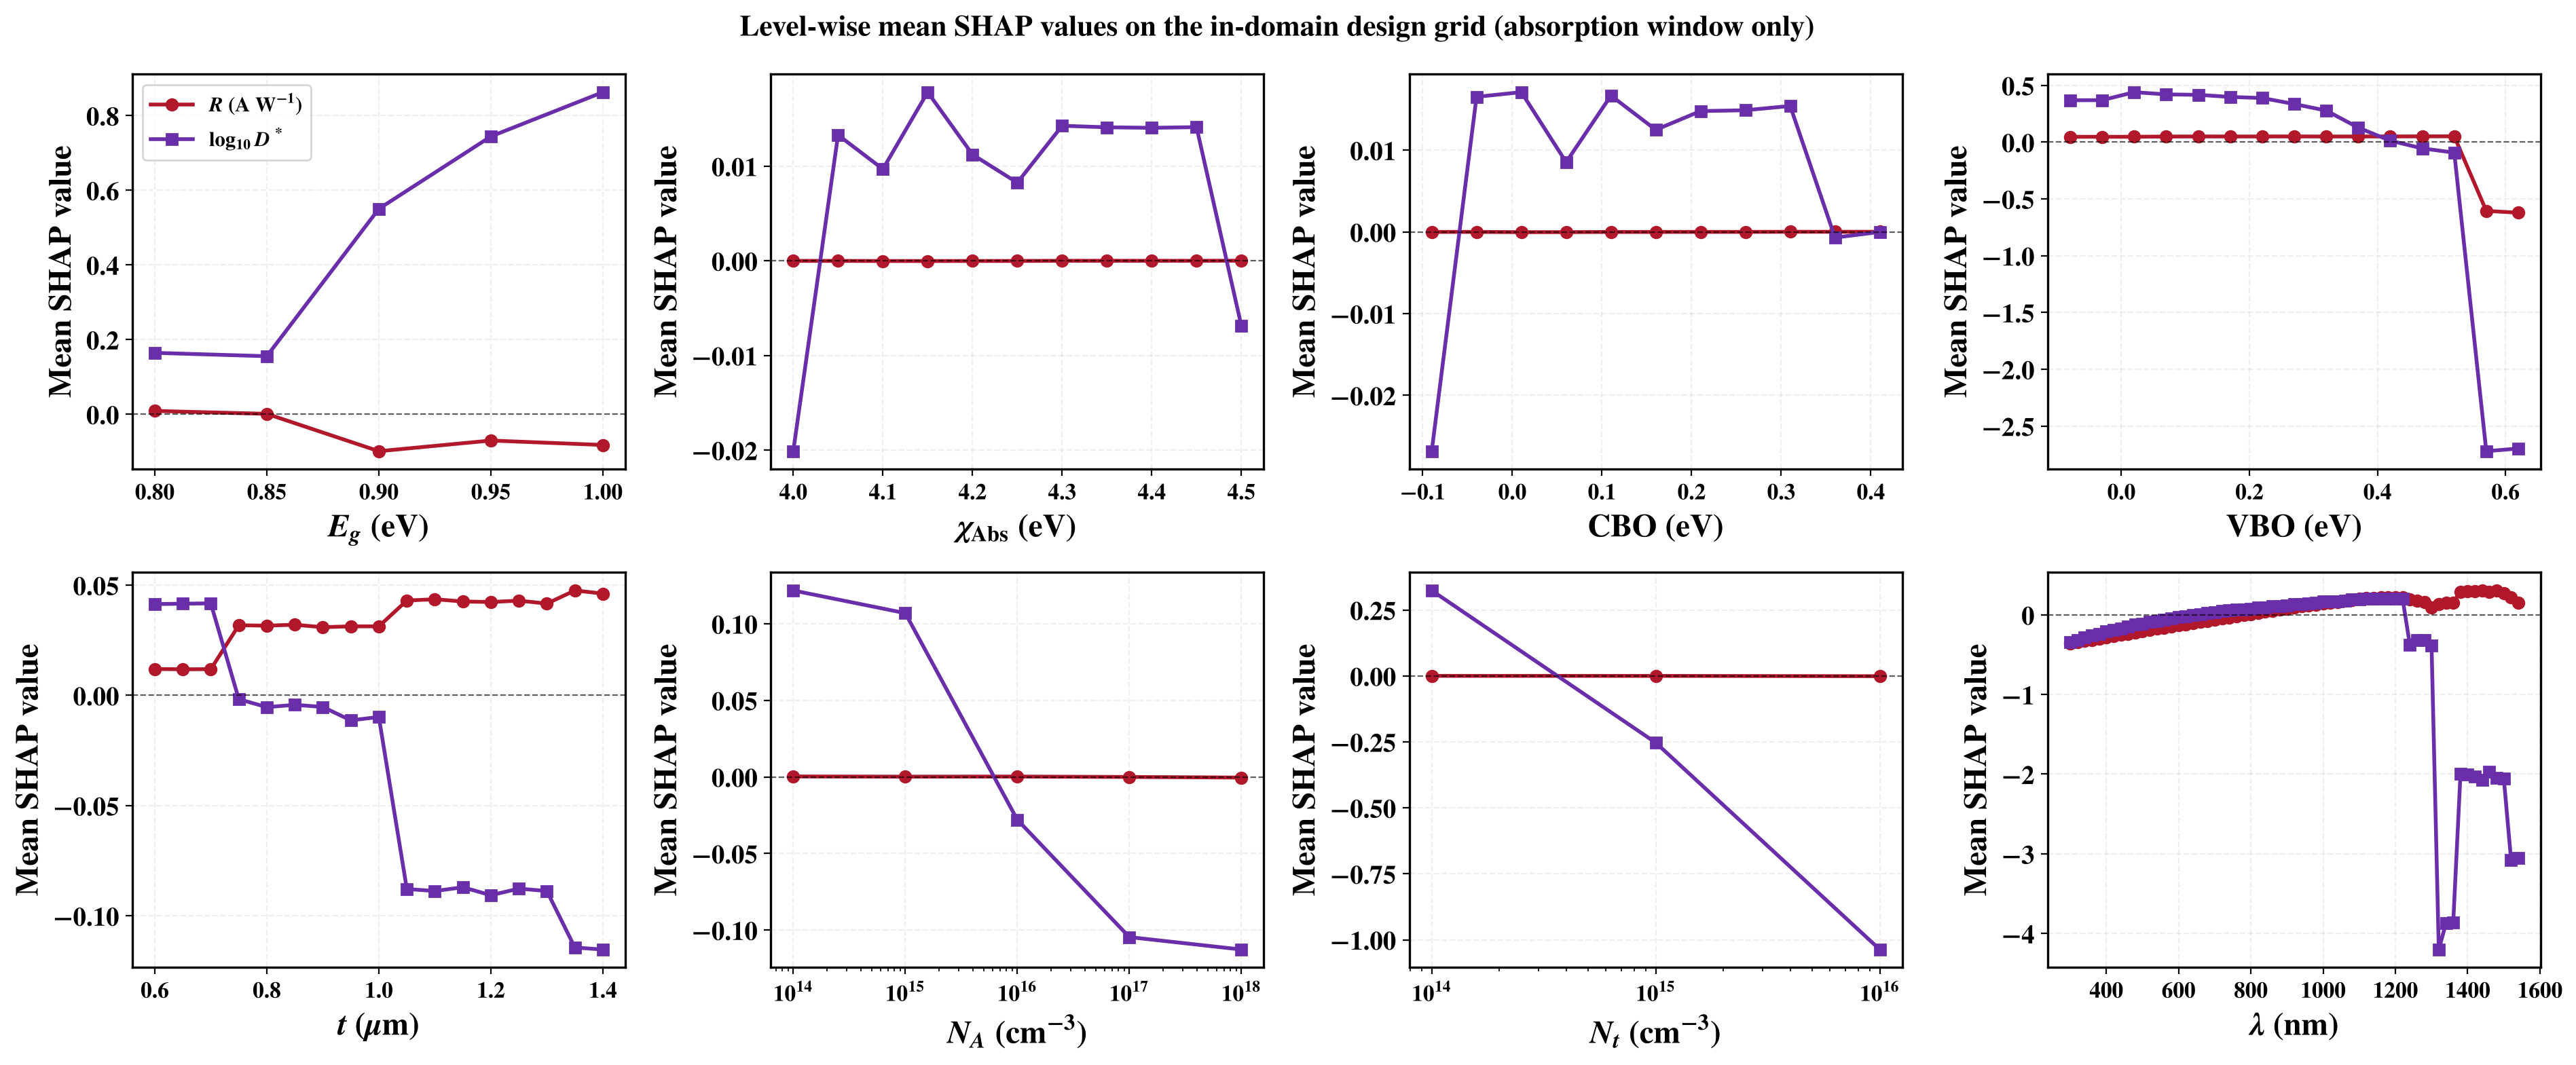

In [21]:
# Level-wise SHAP trends as a compact figure (one panel per parameter, both targets)
fig, axes = plt.subplots(2, 4, figsize=(19, 8), dpi=200)
for ax, p in zip(axes.ravel(), DESIGN_PARAMS):
    sub = level_shap[level_shap["Parameter"] == p]
    for target, color, marker, lab in [("Responsivity", "#B2182B", "o", r"$R$ (A W$^{-1}$)"),
                                       ("log10(Detectivity)", "#6A2EAA", "s", r"$\log_{10}D^*$")]:
        s = sub[sub["Target"] == target].sort_values("Level")
        ax.plot(s["Level"], s["Mean_SHAP"], marker=marker, color=color, linewidth=2, markersize=6, label=lab)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    if p in {"N_A", "N_t"}:
        ax.set_xscale("log")
    ax.set_xlabel(f"{FEATURE_LABELS[p]} ({UNITS_TEX[p]})")
    ax.set_ylabel("Mean SHAP value")
    ax.grid(alpha=0.2, linestyle="--")
axes[0, 0].legend(frameon=True, fontsize=11)
fig.suptitle("Level-wise mean SHAP values on the in-domain design grid (absorption window only)", fontweight="bold")
fig.tight_layout()
save_tiff(fig, "SHAP_Level_Trends.tiff")
plt.show(); plt.close(fig)

## 14. Near-optimal parameter ranges for each target 

Ranges are taken over in-domain candidates (inside the SCAPS training ranges) and inside each candidate's absorption window
($\lambda \le hc/E_g$). *High-R region*: predicted $R$ within 5% of the in-domain maximum. *High-$D^*$ region*: predicted
$D^*$ within a factor of 2 (0.3 decade) of the in-domain maximum. The constrained optimum from Section 9 is listed for comparison.

In [22]:
in_domain = (
    (df_results["Eg"] <= 1.0 + 1e-9) & (df_results["Affinity"] >= 4.0 - 1e-9) & (df_results["t"] <= 1.4 + 1e-9)
    & (df_results["N_A"] >= 1e14 * (1 - 1e-9)) & (df_results["N_t"] <= 1e16 * (1 + 1e-9))
)
in_band = df_results["Wavelength"] <= 1239.84 / df_results["Eg"]
pool_dom = df_results[in_domain & in_band]

high_R = pool_dom[pool_dom["Pred_Responsivity"] >= 0.95 * pool_dom["Pred_Responsivity"].max()]
high_D = pool_dom[np.log10(pool_dom["Pred_Detectivity"]) >= np.log10(pool_dom["Pred_Detectivity"].max()) - np.log10(2)]


def rng(df, col):
    lo, hi = df[col].min(), df[col].max()
    if col in {"N_A", "N_t"}:
        return f"{lo:.0e}" if np.isclose(lo, hi) else f"{lo:.0e} to {hi:.0e}"
    fmt = "{:.0f}" if col == "Wavelength" else "{:.2f}"
    return fmt.format(lo) if np.isclose(lo, hi) else f"{fmt.format(lo)} to {fmt.format(hi)}"


units = {"Eg": "eV", "Affinity": "eV", "t": "um", "N_A": "cm-3", "N_t": "cm-3", "Wavelength": "nm", "CBO": "eV", "VBO": "eV"}
table8 = pd.DataFrame({
    "Unit": [units[c] for c in FEATURES],
    "High-R region": [rng(high_R, c) for c in FEATURES],
    "High-D* region": [rng(high_D, c) for c in FEATURES],
    "Selected design": [f"{best_c[c]:.0e}" if c in {"N_A", "N_t"} else (f"{best_c[c]:.0f}" if c == "Wavelength" else f"{best_c[c]:.2f}")
                        for c in FEATURES],
}, index=FEATURES)
perf = pd.DataFrame({
    "Unit": ["A/W", "Jones"],
    "High-R region": [f"{high_R['Pred_Responsivity'].min():.3f} to {high_R['Pred_Responsivity'].max():.3f}",
                      f"{high_R['Pred_Detectivity'].min():.2e} to {high_R['Pred_Detectivity'].max():.2e}"],
    "High-D* region": [f"{high_D['Pred_Responsivity'].min():.3f} to {high_D['Pred_Responsivity'].max():.3f}",
                       f"{high_D['Pred_Detectivity'].min():.2e} to {high_D['Pred_Detectivity'].max():.2e}"],
    "Selected design": [f"{best_c['Pred_Responsivity']:.3f}", f"{best_c['Pred_Detectivity']:.2e}"],
}, index=["Predicted R", "Predicted D*"])
table8 = pd.concat([table8, perf])
table8.to_csv("results/Table8_Optimal_Ranges.csv")
print(f"In-domain, in-band candidates: {len(pool_dom):,} | high-R region: {len(high_R):,} | high-D* region: {len(high_D):,}")
display(table8)

In-domain, in-band candidates: 765,765 | high-R region: 8,480 | high-D* region: 9,096


,Unit,High-R region,High-D* region,Selected design
Eg,eV,0.80 to 0.85,0.95 to 1.00,1.00
Affinity,eV,4.05 to 4.50,4.20 to 4.40,4.20
t,um,1.05 to 1.40,0.60 to 1.40,1.35
N_A,cm-3,1e+14 to 1e+18,1e+14 to 1e+17,1e+15
N_t,cm-3,1e+14 to 1e+16,1e+14,1e+14
Wavelength,nm,1380 to 1520,480 to 1220,1160
CBO,eV,-0.04 to 0.41,0.11 to 0.31,0.11
VBO,eV,0.07 to 0.52,0.02 to 0.22,0.22
Predicted R,A/W,1.098 to 1.155,0.387 to 0.912,0.911
Predicted D*,Jones,5.70e+13 to 2.72e+16,3.40e+17 to 6.81e+17,4.60e+17
